# Soup take-home: LoRA → merge → 4-bit → SHIP / DON'T SHIP (Qwen2.5-1.5B-Instruct, Russian, Colab T4)

Run top to bottom on a **free Colab T4** (Runtime → Change runtime type → T4 GPU). The kit lives in `/content/soup-task`
(clone or upload, see `README.md`). Outputs: `logs/` (raw, timestamped) and `outputs/` (JSON, tables, plots), all zipped at the end.

| § | Step | T4 time (expected, not measured) |
|---|---|---|
| 0 | Setup, versions, logging, nvidia-smi sampler, Soup CLI discovery | 4–7 min |
| 1 | Data: download, filter, dedupe, leakage check, length stats; template + loss-mask check | 2–4 min |
| 2 | Memory budget **before training** (+ `soup profile`, CUDA context calibration) | ~1 min |
| 3 | Soup data checks ("data doctor") + pre-flight (`soup doctor`, `soup plan`, `soup train --dry-run`) | 2–4 min |
| 3b | Fault injection: do Soup's checks catch deliberately broken inputs? (optional) | 5–8 min |
| 4 | Training with `soup train` (LoRA r=16, fp16, 2 epochs × 1,500 rows) | 20–30 min |
| 5 | Merge (`soup merge`) and 4-bit NF4 (`soup merge --save-format 4bit`) | 6–10 min |
| 6 | Negative control: same pipeline, lr ≈ 0 | 5–8 min |
| 7 | Verification `verify_trained.py` (base / adapter / merged / 4-bit / control) + NC2 | 10–15 min |
| 8 | `soup ship` (optional) | 15–25 min |
| 9 | Silent-failure static checks, memory estimate vs measured, numbers for the report, zip | ~2 min |

Total ≈ 75–95 min. Long steps run **in the background** and the cell only waits `MAX_WAIT_S` seconds (env `KIT_MAX_WAIT_S`,
default 1500); if a cell returns "still running", run it again: it resumes waiting and never starts a second copy.

**Rules this notebook follows:** the kernel never touches CUDA (every GPU step is a subprocess with its own peak-memory record,
so nvidia-smi numbers can be attributed); every cell can be re-run (finished steps are skipped unless forced); no number in the
report is typed by hand: `outputs/report_numbers.md` is generated from the run's files. Failed steps are kept, not hidden.

### Why Soup is the primary stack, and what the fallback is for
* The task is posed by the Soup team, and part 3 asks whether **Soup's own checks** (data doctor, pre-flight, `soup ship`) catch
  silent failures. That can only be answered by running the real pipeline through Soup: `soup train` → `soup merge` →
  `soup merge --save-format 4bit` → `soup ship`.
* Soup wraps transformers + PEFT + TRL, so the artifacts are standard HF/PEFT files and can be checked independently of Soup.
  `verify_trained.py` does not import Soup.
* **Fallback** (clearly labelled cells, run only if a Soup step fails): the same hyper-parameters with plain
  transformers + peft + bitsandbytes (`kit_common.py fallback-*`). If it is used, the report must say which steps fell back and why.

### Choices
* **Model `Qwen/Qwen2.5-1.5B-Instruct`** (Apache-2.0): ≤3B, strong multilingual base with a clean ChatML template, fits a T4 in
  fp16 with room for activations. The checkpoint is **bf16**; T4 (sm_75) has no bf16 hardware, so it is trained in **fp16**
  (bf16→fp16 conversion and fp16 overflow are checked, see E2/B3).
* **Dataset `d0rj/alpaca-cleaned-ru`** (CC-BY-4.0, 51,760 rows, columns `instruction/input/output`, plain parquet). Chosen over
  `IlyaGusev/ru_turbo_alpaca` / `ru_turbo_saiga`, which ship only a loading script + `.jsonl.zst` that current `datasets` no longer
  executes. Caveats: machine-translated from alpaca-cleaned (originally text-davinci-003 outputs), so translation artefacts exist,
  and the upstream licence chain includes OpenAI-generated text. Russian is a language the candidate evaluates natively.
* **Sample**: fixed seed 42; filter (empty, code blocks, <60 % Cyrillic answers), exact + near-duplicate removal, 200 held-out eval
  rows first, then 1,500 train rows with no near-duplicate (word-3-gram Jaccard ≥ 0.6) of any eval row.
* **LoRA** r=16, α=32 (scale 2.0), dropout 0.05, all 7 linear projections, lr 2e-4 cosine, warm-up 3 %, 2 epochs,
  micro-batch 2 × grad-accum 8 (effective 16), max_length 1024 (rows longer are dropped, never truncated), gradient checkpointing.
  Micro-batch 2 (not 4) because the memory budget (§2) shows logits dominate: 152k vocab × tokens × ~14 B.

## 0. Setup (≈4–7 min on first run)
Installs `soup-cli[train]` only if missing, checks bitsandbytes and the torchao/peft conflict that Soup's own T4 notebook
documents, and prints versions **in a subprocess** (so this kernel never initialises CUDA).

In [1]:
import os, sys, subprocess, shutil, importlib.util, json
WORK = "/content/soup-task"
REPO_URL = os.environ.get("SOUP_TASK_REPO", "")   # optional git URL of this kit; leave empty if already cloned/uploaded
FORCE_INSTALL = False
if not os.path.exists(f"{WORK}/kit_common.py"):
    if REPO_URL:
        subprocess.run(["git", "clone", REPO_URL, WORK], check=True)
    else:
        raise SystemExit(f"kit files not found in {WORK}: clone the repo there or upload the files (README.md)")
os.chdir(WORK); sys.path.insert(0, WORK); os.makedirs("logs", exist_ok=True)

def pip(*args):
    r = subprocess.run([sys.executable, "-m", "pip", *args], capture_output=True, text=True)
    with open("logs/pip_install.log", "a") as f:
        f.write(f"\n$ pip {' '.join(args)}\n{r.stdout}\n{r.stderr}\n")
    print(f"pip {' '.join(args)} -> rc={r.returncode}")
    return r.returncode

if FORCE_INSTALL or shutil.which("soup") is None or importlib.util.find_spec("soup_cli") is None:
    pip("install", "-q", "soup-cli[train]")
if importlib.util.find_spec("bitsandbytes") is None:
    pip("install", "-q", "bitsandbytes")
PROBE = "import peft, peft.import_utils as u; f = getattr(u, 'is_torchao_available', None); print('peft', peft.__version__, 'torchao_available', f() if f else 'n/a')"
chk = subprocess.run([sys.executable, "-c", PROBE], capture_output=True, text=True)
print(chk.stdout.strip() or chk.stderr.strip()[-800:])
if chk.returncode != 0 and "ImportError" in chk.stderr and "torchao" in chk.stderr:
    print("peft refuses the preinstalled torchao (ImportError) -> uninstalling it"); pip("uninstall", "-y", "torchao")

VERSIONS = r"""
import sys, json, importlib
out = {"python": sys.version.split()[0]}
for m in ["torch", "transformers", "peft", "trl", "accelerate", "datasets", "bitsandbytes", "safetensors", "soup_cli", "numpy"]:
    try:
        out[m] = getattr(importlib.import_module(m), "__version__", "?")
    except Exception as e:
        out[m] = "MISSING: " + repr(e)[:150]
import torch
out["cuda_available"] = torch.cuda.is_available()
if torch.cuda.is_available():
    out.update(gpu=torch.cuda.get_device_name(0), capability=list(torch.cuda.get_device_capability(0)),
               total_mem_gib=torch.cuda.get_device_properties(0).total_memory / 2**30, torch_cuda=torch.version.cuda,
               bf16_supported_incl_emulation=torch.cuda.is_bf16_supported())
    try:
        out["bf16_in_hardware"] = torch.cuda.is_bf16_supported(including_emulation=False)
    except TypeError:
        out["bf16_in_hardware"] = "n/a in this torch"
print(json.dumps(out))
"""
ver = subprocess.run([sys.executable, "-c", VERSIONS], capture_output=True, text=True)
print(ver.stdout or ver.stderr[-2000:])
open("logs/versions.json", "w").write(ver.stdout)
subprocess.run(f"{sys.executable} -m pip freeze > logs/pip_freeze.txt 2>&1", shell=True)
subprocess.run("nvidia-smi > logs/nvidia_smi_initial.txt 2>&1; free -m > logs/ram_initial.txt; df -h /content > logs/disk_initial.txt; "
               "nproc > logs/cpu_count.txt", shell=True)
print(open("logs/nvidia_smi_initial.txt").read())

pip install -q soup-cli[train] -> rc=0


Traceback (most recent call last):
  File "<string>", line 1, in <module>
    import peft, peft.import_utils as u; f = getattr(u, 'is_torchao_available', None); print('peft', peft.__version__, 'torchao_available', f() if f else 'n/a')
                                                                                                                                            ~^^
  File "/usr/local/lib/python3.13/dist-packages/peft/import_utils.py", line 162, in is_torchao_available
    raise ImportError(
    ...<2 lines>...
    )
ImportError: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported
peft refuses the preinstalled torchao (ImportError) -> uninstalling it


pip uninstall -y torchao -> rc=0


{"python": "3.13.16", "torch": "2.14.1+cu130", "transformers": "5.22.1", "peft": "0.21.2", "trl": "0.29.1", "accelerate": "1.15.0", "datasets": "4.8.5", "bitsandbytes": "0.50.2", "safetensors": "0.8.0", "soup_cli": "0.77.2", "numpy": "2.4.6", "cuda_available": true, "gpu": "Tesla T4", "capability": [7, 5], "total_mem_gib": 14.56317138671875, "torch_cuda": "13.0", "bf16_supported_incl_emulation": true, "bf16_in_hardware": false}



Wed Nov 11 17:40:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P0             27W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 0.1 Logging and the nvidia-smi sampler (≈5 s)
* `logs/run.log`: Python logging, every stage START/END with millisecond timestamps.
* `logs/nvidia_smi.log`: **raw** `nvidia-smi --query-gpu=timestamp,…,memory.used,… --format=csv -l 1` for the whole session.
  1 s instead of 5 s because the loss/logits spike lasts well under 5 s; it can still miss sub-second peaks, which is why every GPU
  subprocess also records `torch.cuda.max_memory_allocated/reserved` at exit (`logs/peak_*.json`).
* `logs/nvidia_smi_snapshots.log`: full `nvidia-smi` + per-process memory at the start and end of every stage.
* `logs/cmd/<step>.log`: every command's output, one timestamp per line; `logs/stage_memory.jsonl`: per-stage memory summary.

In [2]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

K.start_gpu_sampler(interval_s=K.NVSMI_INTERVAL_S)
K.nvsmi_snapshot("session start")
K.log.info("logging ready")

2026-11-11T17:40:54.659 INFO SESSION init: WORK=/content/soup-task tz=('UTC', 'UTC') python=3.13.16 pid=727


2026-11-11T17:40:54.662 INFO nvidia-smi sampler started pid=1095 every 1s -> logs/nvidia_smi.log


2026-11-11T17:40:54.845 INFO logging ready


### 0.2 What does the installed Soup actually offer? (≈1–2 min)
The local docs describe v0.75; PyPI may be newer. Every subcommand's `--help` is saved to `logs/soup_help/` and the notebook
adapts (e.g. `soup merge --adapter X` vs `soup merge X`, whether `soup data doctor` exists).

In [3]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

with K.stage("soup_cli_discovery"):
    caps = K.soup_caps(refresh=True)
print(json.dumps(caps, indent=1))
for n in ["help_root", "help_train", "help_merge", "help_data", "help_ship", "help_profile"]:
    print(f"\n===== soup {n[5:].replace('_', ' ')} --help =====\n" + K.cmd_output(n)[:3500])

2026-11-11T17:40:54.862 INFO STAGE START soup_cli_discovery


2026-11-11T17:40:55.035 INFO [soup_version] started pid=1109: soup --version


2026-11-11T17:40:56.333 INFO [soup_version] finished rc=0


2026-11-11T17:40:56.338 INFO [help_root] started pid=1115: soup --help


2026-11-11T17:40:57.633 INFO [help_root] finished rc=0


2026-11-11T17:40:57.637 INFO [help_train] started pid=1121: soup train --help


... (28 outputs left out)

2026-11-11T17:41:17.093 INFO [help_data_doctor] finished rc=0


2026-11-11T17:41:17.096 INFO soup capabilities: {"checked": "2026-11-11T17:40:55.033+00:00", "soup_on_path": true, "version": "0.77.2", "help_root_rc": 0, "help_train_rc": 0, "help_merge_rc": 0, "help_data_rc": 0, "help_ship_rc": 0, "help_profile_rc": 0, "help_plan_rc": 0, "help_quantize_rc": 0, "help_export_rc": 0, "help_doctor_rc": 0, "help_diagnose_rc": 0, "help_eval_rc": 0, "help_data_validate_rc": 0, "help_data_stats_rc": 0, "help_data_inspect_rc": 0, "data_has_doctor": true, "data_subcommands_seen": ["convert", "decontaminate", "dedup", "doctor", "download", "filter", "inspect", "langdetect", "lint", "preprocess", "preview", "sample", "score", "split", "stats", "validate"], "merge_has_adapter_flag": true, "merge_has_save_format": true, "merge_has_low_memory": true, "merge_has_dtype": true, "train_has_dry_run": true, "train_has_yes": true, "profile_has_json": true, "has_plan": true, "ship_has_tuned": true, "ship_has_general_suite": true, "ship_has_device": true, "eval_has_quant_ch

2026-11-11T17:41:17.326 INFO STAGE END soup_cli_discovery status=ok 22.2s


{
 "checked": "2026-11-11T17:40:55.033+00:00",
 "soup_on_path": true,
 "version": "0.77.2",
 "help_root_rc": 0,
 "help_train_rc": 0,
 "help_merge_rc": 0,
 "help_data_rc": 0,
 "help_ship_rc": 0,
 "help_profile_rc": 0,
 "help_plan_rc": 0,
 "help_quantize_rc": 0,
 "help_export_rc": 0,
 "help_doctor_rc": 0,
 "help_diagnose_rc": 0,
 "help_eval_rc": 0,
 "help_data_validate_rc": 0,
 "help_data_stats_rc": 0,
 "help_data_inspect_rc": 0,
 "data_has_doctor": true,
 "data_subcommands_seen": [
  "convert",
  "decontaminate",
  "dedup",
  "doctor",
  "download",
  "filter",
  "inspect",
  "langdetect",
  "lint",
  "preprocess",
  "preview",
  "sample",
  "score",
  "split",
  "stats",
  "validate"
 ],
 "merge_has_adapter_flag": true,
 "merge_has_save_format": true,
 "merge_has_low_memory": true,
 "merge_has_dtype": true,
 "train_has_dry_run": true,
 "train_has_yes": true,
 "profile_has_json": true,
 "has_plan": true,
 "ship_has_tuned": true,
 "ship_has_general_suite": true,
 "ship_has_device": true,

## 1. Data (≈2–4 min)
Download (revision pinned to the dataset commit sha), filter, exact + near-duplicate removal, **held-out first**, then train rows that
are not near-duplicates of any held-out row; rows longer than 1,024 tokens (rendered with the real chat template) are dropped,
never truncated. Writes `data/train.jsonl` (Soup `chatml` format: only `messages`), `data/eval.jsonl`, `data/nc_train.jsonl`
(64 rows for the negative control), `data/probe_prompts.jsonl`, `data/ship_tasks.jsonl`, `data/data_report.json`.

In [4]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

with K.stage("data_prep"):
    rep = K.prepare_data(force=False)
show = ["dataset", "dataset_revision", "load_method", "n_raw", "n_pool_after_filters", "n_train", "n_eval", "drop_reasons",
        "leakage_audit", "train_vs_eval_max_jaccard", "default_system_prompt_injected"]
print(json.dumps({k: rep.get(k) for k in show}, indent=1, ensure_ascii=False))
print(json.dumps(rep["token_stats"], indent=1))

2026-11-11T17:41:17.340 INFO STAGE START data_prep


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/760 [00:00<?, ?B/s]

data/train-00000-of-00001-c503683bee003a(…): reconstructing file:   0%|          |  0.00B / 36.6MB            

data/train-00000-of-00001-c503683bee003a(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/51760 [00:00<?, ? examples/s]

... (6 outputs left out)

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

2026-11-11T17:41:57.207 INFO data ready: train=1500 eval=200 audit={'eval_user_in_train': 0, 'eval_answer_in_train': 0, 'train_eval_source_index_overlap': 0}


2026-11-11T17:41:57.640 INFO STAGE END data_prep status=ok 40.0s


{
 "dataset": "d0rj/alpaca-cleaned-ru",
 "dataset_revision": "05321f66bb70be21bd1ea2cb8fe3ca18693a688a",
 "load_method": "datasets.load_dataset",
 "n_raw": 51760,
 "n_pool_after_filters": 48740,
 "n_train": 1500,
 "n_eval": 200,
 "drop_reasons": {
  "code_block": 1602,
  "exact_dup_user": 30,
  "output_too_short": 63,
  "low_cyrillic": 960,
  "exact_dup_output": 365
 },
 "leakage_audit": {
  "eval_user_in_train": 0,
  "eval_answer_in_train": 0,
  "train_eval_source_index_overlap": 0
 },
 "train_vs_eval_max_jaccard": {
  "n": 1500,
  "min": 0.0,
  "p50": 0.0,
  "p90": 0.027857142857142782,
  "p95": 0.06666666666666667,
  "p99": 0.14291005291005285,
  "max": 0.25,
  "mean": 0.00846438721712736
 },
 "default_system_prompt_injected": true
}
{
 "train_total": {
  "n": 1500,
  "min": 48,
  "p50": 230.5,
  "p90": 611.0,
  "p95": 690.05,
  "p99": 877.02,
  "max": 994,
  "mean": 288.54533333333336
 },
 "train_prompt": {
  "n": 1500,
  "min": 36,
  "p50": 53.0,
  "p90": 79.0,
  "p95": 96.0499999

### 1.1 Chat template and loss mask (≈30 s, CPU)
Train and inference must render conversations identically, the answer must end with `<|im_end|>` **inside** the trained span (or the
model never learns to stop), and user/system tokens must not be trained. This cell uses the same `encode_example()` that
`verify_trained.py` evaluates with, and, if this Soup version exposes it, Soup's own mask builder
(`soup_cli.data.loss_mask.build_assistant_only_labels`) to compare exactly which tokens Soup trains.

In [5]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

with K.stage("template_mask_check"):
    tc = K.masking_check(n=50)
print(json.dumps({k: v for k, v in tc.items() if k != "example_render"}, indent=1, ensure_ascii=False))
print("\n--- example render (answer span that our eval scores is marked) ---\n" + tc["example_render"])

2026-11-11T17:41:57.655 INFO STAGE START template_mask_check


[transformers] return_assistant_tokens_mask==True but chat template does not contain `{% generation %}` keyword.


2026-11-11T17:42:00.339 INFO STAGE END template_mask_check status=ok 2.4s


{
 "n": 50,
 "tokenizer": {
  "eos": "<|im_end|>",
  "eos_id": 151645,
  "pad": "<|endoftext|>",
  "pad_id": 151643,
  "bos": null,
  "pad_is_eos": false
 },
 "soup_mask_function": "soup_cli.data.loss_mask.build_assistant_only_labels",
 "counts": {
  "ours_eos_in_answer": 50,
  "prefix_tokens_match": 50,
  "content_exact": 50,
  "soup_same_input_ids": 50,
  "soup_eos_trained": 50,
  "soup_prompt_tokens_trained": 0,
  "soup_covers_all_our_answer_tokens": 50
 },
 "soup_trains_extra_tokens": {
  "\n": 100,
  "<|im_start|>": 50,
  "assistant": 50
 },
 "full_render_sha": "3f2665f833e4a268"
}

--- example render (answer span that our eval scores is marked) ---
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Составьте список из трех советов по безопасности, которым дети должны следовать по дороге в школу.<|im_end|>
<|im_start|>assistant
[[TRAINED>>1. Придерживайтесь тротуаров: всегда ходите по обозначенным тротуарам или пешехо

### 1.2 Soup configs
`soup.yaml` (main run), `soup_min.yaml` (only the essential keys, used if this Soup version rejects a key: since v0.75 unknown keys
fail the load), `soup_nc.yaml` (negative control). `quantization: none` is explicit: Soup's default is `4bit` (QLoRA), which would
silently change the method.

In [6]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

K.write_soup_config(K.WORK / "soup.yaml", K.soup_config_dict(K.HP, K.DATA / "train.jsonl", K.SOUP_RUN), header="main LoRA run")
K.write_soup_config(K.WORK / "soup_min.yaml", K.soup_config_dict(K.HP, K.DATA / "train.jsonl", K.SOUP_RUN, minimal=True),
                    header="minimal config: used only if soup.yaml is rejected by the dry-run")
K.write_soup_config(K.WORK / "soup_nc.yaml", K.soup_config_dict(K.NC_HP, K.DATA / "nc_train.jsonl", K.NC_RUN),
                    header="negative control: identical pipeline, lr ~ 0 (Soup requires lr > 0), 64 rows, 1 epoch")
for f in ["soup.yaml", "soup_nc.yaml"]:
    print(f"----- {f}\n" + open(f).read())

2026-11-11T17:42:00.359 INFO wrote soup.yaml


2026-11-11T17:42:00.361 INFO wrote soup_min.yaml


2026-11-11T17:42:00.363 INFO wrote soup_nc.yaml


----- soup.yaml
# main LoRA run
base: Qwen/Qwen2.5-1.5B-Instruct
task: sft
backend: transformers
data:
  train: data/train.jsonl
  format: chatml
  max_length: 1024
  val_split: 0.0
  train_on_responses_only: true
training:
  epochs: 2
  lr: 2.000e-04
  batch_size: 2
  gradient_accumulation_steps: 8
  quantization: none
  gradient_checkpointing: true
  seed: 42
  warmup_ratio: 0.03
  weight_decay: 0.0
  max_grad_norm: 1.0
  scheduler: cosine
  optimizer: adamw_torch
  logging_steps: 5
  save_steps: 50
  lora:
    r: 16
    alpha: 32
    dropout: 0.05
    target_modules: [q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj]
output: outputs/soup_run

----- soup_nc.yaml
# negative control: identical pipeline, lr ~ 0 (Soup requires lr > 0), 64 rows, 1 epoch
base: Qwen/Qwen2.5-1.5B-Instruct
task: sft
backend: transformers
data:
  train: data/nc_train.jsonl
  format: chatml
  max_length: 1024
  val_split: 0.0
  train_on_responses_only: true
training:
  epochs: 1
  lr: 1.000e-09
  b

## 2. Memory budget BEFORE training (≈1 min)
`memory_budget.py` computes the budget from the model's `config.json` and the run parameters: fp16 base weights, LoRA parameters
per module type, fp32 adapter + grads + AdamW states, activations with gradient checkpointing, **logits** (B × T × 151,936 × bytes
incl. fp32 upcast for the loss), allocator + CUDA context, merge and 4-bit quantization peaks. Formulas and assumptions are in its
docstring and printed next to the numbers. Three length scenarios: config ceiling (1024), the longest row in the data (sets the
**peak**, because dynamic padding pads its batch partner up to it), the median row.

Also recorded: Soup's own estimate (`soup profile`) and a CUDA-context calibration (a process holding 4 MiB of tensors: whatever
nvidia-smi shows beyond that is memory torch cannot see).

In [7]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

with K.stage("memory_budget"):
    ctx = K.measure_cuda_context()
    ctx_gib = ctx.get("context_overhead_gib")
    args = [sys.executable, "memory_budget.py", "--model", K.MODEL_ID, "--batch-size", str(K.HP["batch_size"]),
            "--grad-accum", str(K.HP["grad_accum"]), "--seq-len", str(K.MAX_LEN), "--data-report", "data/data_report.json",
            "--lora-r", str(K.HP["lora_r"]), "--lora-alpha", str(K.HP["lora_alpha"]), "--lora-dropout", str(K.HP["lora_dropout"]),
            "--target-modules", ",".join(K.TARGET_MODULES), "--out", "outputs/memory_budget.json"]
    if isinstance(ctx_gib, (int, float)) and ctx_gib > 0:
        args += ["--cuda-context-gib", f"{ctx_gib:.3f}"]   # measured, replaces the 0.40 GiB assumption
    rc, out = K.run_cmd("memory_budget", args, timeout_s=300, quiet=True)
    caps = K.soup_caps()
    rc_p, out_p = K.run_cmd("soup_profile", ["soup", "profile", "--config", "soup.yaml"], timeout_s=300, quiet=True)
    if caps.get("profile_has_json"):
        rc_j, out_j = K.run_cmd("soup_profile_json", ["soup", "profile", "--config", "soup.yaml", "--json"], timeout_s=300, quiet=True)
        try:
            K.write_json(K.OUT / "soup_profile.json", json.loads(out_j[out_j.index("{"): out_j.rindex("}") + 1]))
        except Exception as e:
            print("could not parse soup profile --json:", repr(e))
print("CUDA context calibration:", json.dumps(ctx))
print(out)
print("\n===== soup profile (Soup's own estimate) =====\n" + out_p[-4000:])

2026-11-11T17:42:00.384 INFO STAGE START memory_budget


2026-11-11T17:42:00.562 INFO [cuda_context_probe] started pid=1472: /usr/bin/python3 -c 
import json, time, torch
torch.cuda.init()
a = torch.randn(1024, 1024, device="cuda", dtype=torch.float16)
b = a @ a                     # forces cuBLAS handle + workspace
torch.cuda.synchronize()
print(json.dumps({"torch_allocated_gib": torch.cuda.memory_allocated() / 2**30,
                  "torch_reserved_gib": torch.cuda.memory_reserved() / 2**30}), flush=True)
time.sleep(6)                 # let the 1 s nvidia-smi sampler see it



2026-11-11T17:42:11.339 INFO [cuda_context_probe] finished rc=0


2026-11-11T17:42:11.341 INFO CUDA context calibration: {'rc': 0, 'nvsmi_max_used_gib': 0.1357421875, 'nvsmi_baseline_gib': 0.0029296875, 'torch_allocated_gib': 0.0118408203125, 'torch_reserved_gib': 0.01953125, 'context_overhead_gib': 0.11328125}


2026-11-11T17:42:11.345 INFO [memory_budget] started pid=1521: /usr/bin/python3 memory_budget.py --model Qwen/Qwen2.5-1.5B-Instruct --batch-size 2 --grad-accum 8 --seq-len 1024 --data-report data/data_report.json --lora-r 16 --lora-alpha 32 --lora-dropout 0.05 --target-modules q_proj,k_proj,v_proj,o_proj,gate_proj,up_proj,down_proj --out outputs/memory_budget.json --cuda-context-gib 0.113


2026-11-11T17:42:12.641 INFO [memory_budget] finished rc=0


... (2 outputs left out)

2026-11-11T17:42:19.233 INFO [soup_profile_json] started pid=1561: soup profile --config soup.yaml --json


2026-11-11T17:42:25.814 INFO [soup_profile_json] finished rc=0


2026-11-11T17:42:26.043 INFO STAGE END memory_budget status=ok 25.4s


CUDA context calibration: {"rc": 0, "nvsmi_max_used_gib": 0.1357421875, "nvsmi_baseline_gib": 0.0029296875, "torch_allocated_gib": 0.0118408203125, "torch_reserved_gib": 0.01953125, "context_overhead_gib": 0.11328125}
$ /usr/bin/python3 memory_budget.py --model Qwen/Qwen2.5-1.5B-Instruct --batch-size 2 --grad-accum 8 --seq-len 1024 --data-report data/data_report.json --lora-r 16 --lora-alpha 32 --lora-dropout 0.05 --target-modules q_proj,k_proj,v_proj,o_proj,gate_proj,up_proj,down_proj --out outputs/memory_budget.json --cuda-context-gib 0.113
Model config from: /root/.cache/huggingface/hub/models--Qwen--Qwen2.5-1.5B-Instruct/snapshots/989aa7980e4cf806f80c7fef2b1adb7bc71aa306/config.json
Params total 1,543,714,304 (embed 233,373,696, layers 1,310,339,072, tied=True, qkv_bias=True)
LoRA r=16 alpha=32 scale=2: 18,464,768 params in 196 modules (1.20% of base)
   q_proj     in=1536  out=1536  r*(in+out)=  49,152  x layers =   1,376,256
   k_proj     in=1536  out=256   r*(in+out)=  28,672  x

## 3. Soup's built-in checks: "data doctor" and pre-flight (≈2–4 min)
* **Data doctor**: `soup data validate` / `stats` / `inspect`, plus `soup data doctor --model … --max-length 1024` and its
  `--show-mask` X-ray **if this version has it** (the v0.75 docs list 8 checks: chat_template, template_render, generation_markers,
  eos_in_labels, bos_duplication, system_role, unknown_roles, truncation_risk).
* **Pre-flight**: `soup doctor` (environment, `--config` lists settings the backend will not read), `soup plan` and
  `soup train --dry-run` (config + data validation; in v0.75 the VRAM gate prints only when a run does **not** fit).

In [8]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

caps = K.soup_caps()
res = {}
with K.stage("soup_data_checks"):
    for name, args in [("soup_data_validate", ["soup", "data", "validate", "data/train.jsonl"]),
                       ("soup_data_validate_eval", ["soup", "data", "validate", "data/eval.jsonl"]),
                       ("soup_data_stats", ["soup", "data", "stats", "data/train.jsonl"]),
                       ("soup_data_inspect", ["soup", "data", "inspect", "data/train.jsonl"])]:
        res[name], out = K.run_cmd(name, args, timeout_s=600, quiet=True)
        print(f"\n===== {' '.join(args)}  (rc={res[name]}) =====\n" + out[-3000:])
    if caps.get("data_has_doctor"):
        dh = K.cmd_output("help_data_doctor")
        base_args = ["soup", "data", "doctor", "data/train.jsonl", "--model", K.MODEL_ID, "--max-length", str(K.MAX_LEN)]
        args = base_args + (["--output", "outputs/soup_data_doctor.json"] if "--output" in dh else [])
        res["soup_data_doctor"], out = K.run_cmd("soup_data_doctor", args, timeout_s=900, quiet=True)
        print(f"\n===== soup data doctor (rc={res['soup_data_doctor']}) =====\n" + out[-4000:])
        if "--show-mask" in dh:
            rc, out = K.run_cmd("soup_data_doctor_mask", base_args + ["--show-mask", "2"], timeout_s=900, quiet=True)
            print("\n===== soup data doctor --show-mask 2 =====\n" + out[-4000:])
    else:
        print("\n`soup data doctor` does not exist in this Soup version: covered by validate + stats + our §1.1 mask check.")
K.write_json(K.OUT / "soup_data_checks.json", res)

2026-11-11T17:42:26.059 INFO STAGE START soup_data_checks


2026-11-11T17:42:26.200 INFO [soup_data_validate] started pid=1603: soup data validate data/train.jsonl


2026-11-11T17:42:27.496 INFO [soup_data_validate] finished rc=0



===== soup data validate data/train.jsonl  (rc=0) =====
$ soup data validate data/train.jsonl
Auto-detected format: chatml
Dataset is valid!
1500/1500 rows valid for chatml format
exit code 0 after 0.7s
2026-11-11T17:42:27.500 INFO [soup_data_validate_eval] started pid=1613: soup data validate data/eval.jsonl


2026-11-11T17:42:28.794 INFO [soup_data_validate_eval] finished rc=0



===== soup data validate data/eval.jsonl  (rc=0) =====
$ soup data validate data/eval.jsonl
Auto-detected format: chatml
Dataset is valid!
200/200 rows valid for chatml format
exit code 0 after 0.7s
2026-11-11T17:42:28.797 INFO [soup_data_stats] started pid=1619: soup data stats data/train.jsonl


... (5 outputs left out)


===== soup data doctor (rc=0) =====
$ soup data doctor data/train.jsonl --model Qwen/Qwen2.5-1.5B-Instruct --max-length 1024 --output outputs/soup_data_doctor.json
[transformers] return_assistant_tokens_mask==True but chat template does not contain `{% generation %}` keyword.
                                                                                          soup data doctor                                                                                           
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Check              ┃ Verdict ┃ Message                                                                                                                                    ┃ Evidence              ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

2026-11-11T17:42:52.945 INFO [soup_data_doctor_mask] finished rc=0



===== soup data doctor --show-mask 2 =====
½ÑĭÐ¼ĠÑĤÑĢÐ¾ÑĤÑĥÐ°ÑĢÐ°Ð¼ĠÐ¸Ð»Ð¸ĠÐ¿ÐµÑĪÐµÑħÐ¾Ð´Ð½ÑĭÐ¼ĠÐ´Ð¾ÑĢÐ¾Ð¶ÐºÐ°Ð¼,ĠÐºÐ¾Ð³Ð´Ð°ĠÐ¸Ð´ÐµÑĤÐµĠÐ²ĠÑĪÐºÐ¾Ð»Ñĥ.ĠÐķÑģÐ»Ð¸ĠÑĤÑĢÐ¾ÑĤÑĥÐ°ÑĢÐ°ĠÐ½ÐµÑĤ,ĠÐ¸Ð´Ð¸ÑĤÐµĠÐ»Ð │
│ ¸ÑĨÐ¾Ð¼ĠÐºĠÐ´Ð²Ð¸Ð¶ÐµÐ½Ð¸Ñİ,ĠÐºÐ°ÐºĠÐ¼Ð¾Ð¶Ð½Ð¾ĠÐ´Ð°Ð»ÑĮÑĪÐµĠÐ¾ÑĤĠÐ´Ð¾ÑĢÐ¾Ð³Ð¸.ĊĊ2.ĠÐ¡Ð¾Ð±Ð»ÑİÐ´Ð°Ð¹ÑĤÐµĠÐ¿ÑĢÐ°Ð²Ð¸Ð»Ð°ĠÐ´Ð¾ÑĢÐ¾Ð¶Ð½Ð¾Ð³Ð¾ĠÐ´Ð²Ð¸Ð¶ÐµÐ½Ð¸Ñı:ĠÐ²ÑģÐµÐ³Ð´Ð°ĠÑģÐ»ÐµÐ´ÑĥÐ¹ÑĤÐµĠÑģÐ¸Ð³Ð½Ð° │
│ Ð»Ð°Ð¼ĠÑģÐ²ÐµÑĤÐ¾ÑĦÐ¾ÑĢÐ°,ĠÐ±ÑĥÐ´ÑĮÑĤÐµĠÐ±Ð´Ð¸ÑĤÐµÐ»ÑĮÐ½ÑĭĠÐ¸ĠÐ¿ÐµÑĢÐµÑħÐ¾Ð´Ð¸ÑĤÐµĠÐ´Ð¾ÑĢÐ¾Ð³ÑĥĠÑĤÐ¾Ð»ÑĮÐºÐ¾ĠÐ½Ð°ĠÐ·ÐµÐ»ÐµÐ½ÑĭÐ¹ĠÑģÐ¸Ð³Ð½Ð°Ð»ĠÑģÐ²ÐµÑĤÐ¾ÑĦÐ¾ÑĢÐ°.ĠÐŁÐµÑĢÐµÐ´ĠÐ¿ÐµÑĢÐµÑħÐ¾Ð´Ð¾Ð¼ĠÐ¿Ð¾ │
│ ÑģÐ¼Ð¾ÑĤÑĢÐ¸ÑĤÐµĠÐ½Ð°Ð»ÐµÐ²Ð¾,ĠÐ½Ð°Ð¿ÑĢÐ°Ð²Ð¾ĠÐ¸ĠÐµÑīÐµĠÑĢÐ°Ð·ĠÐ½Ð°Ð»ÐµÐ²Ð¾,ĠÑĩÑĤÐ¾Ð±ÑĭĠÑĥÐ±ÐµÐ´Ð¸ÑĤÑĮÑģÑı,ĠÑĩÑĤÐ¾ĠÐ¼Ð°ÑĪÐ¸Ð½ÑĭĠÐ½ÐµĠÐµÐ´ÑĥÑĤ.ĊĊ3.ĠÐĳÑĥÐ´ÑĮÑĤÐµĠÐ½Ð°ĠÐ²Ð¸Ð´Ñĥ:ĠÐ½Ð¾ÑģÐ¸ÑĤÐµĠÑıÑĢÐºÑĥ │
│ ÑİĠÐ¾Ð´ÐµÐ¶Ð´ÑĥĠÐ¸Ð»Ð¸ĠÑģÐ²ÐµÑĤÐ¾Ð¾ÑĤÑĢÐ°Ð¶Ð°ÑİÑīÐ¸ÐµĠÑģÑĢÐµÐ´ÑģÑĤÐ²Ð°ĠÑĢÐ°Ð½Ð¾ĠÑĥÑĤÑĢÐ¾Ð¼ĠÐ¸Ð»Ð¸ĠÐ½Ð¾ÑĩÑĮÑİ,ĠÑĩÑĤÐ¾Ð±ÑĭĠÐ±ÑĭÑĤÑĮĠÐ±Ð¾Ð»ÐµÐµĠÐ·Ð°Ð¼ÐµÑĤÐ½ÑĭÐ¼Ð¸ĠÐ´Ð»ÑıĠÐ²Ð¾Ð´Ð¸ÑĤÐµÐ»ÐµÐ¹.ĠÐķÑģÐ

2026-11-11T17:42:53.182 INFO STAGE END soup_data_checks status=ok 26.9s


In [9]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

caps = K.soup_caps()
pre = {}
with K.stage("soup_preflight"):
    doc = ["soup", "doctor"] + (["--config", "soup.yaml"] if caps.get("doctor_has_config") else [])
    pre["soup_doctor"], out = K.run_cmd("soup_doctor", doc, timeout_s=600, quiet=True)
    print(f"===== {' '.join(doc)} (rc={pre['soup_doctor']}) =====\n" + out[-3500:])
    if caps.get("has_plan"):
        pre["soup_plan"], out = K.run_cmd("soup_plan", ["soup", "plan", "--config", "soup.yaml"], timeout_s=600, quiet=True)
        print(f"\n===== soup plan (rc={pre['soup_plan']}) =====\n" + out[-3500:])
    train_cfg = "soup.yaml"
    if caps.get("train_has_dry_run"):
        pre["dry_run"], out = K.run_cmd("soup_dry_run", ["soup"] + K.soup_train_args("soup.yaml", dry_run=True), timeout_s=900, quiet=True)
        print(f"\n===== soup train --dry-run (rc={pre['dry_run']}) =====\n" + out[-5000:])
        if pre["dry_run"] != 0:
            pre["dry_run_min"], out = K.run_cmd("soup_dry_run_min", ["soup"] + K.soup_train_args("soup_min.yaml", dry_run=True),
                                                timeout_s=900, quiet=True)
            print(f"\n===== minimal config dry-run (rc={pre['dry_run_min']}) =====\n" + out[-4000:])
            train_cfg = "soup_min.yaml" if pre["dry_run_min"] == 0 else None
    K.set_path("train_config", train_cfg)
K.write_json(K.OUT / "soup_preflight.json", pre)
print("\nconfig used for training:", train_cfg, "(None = both rejected: read the log, fix, or use the fallback in §4)")

2026-11-11T17:42:53.198 INFO STAGE START soup_preflight


2026-11-11T17:42:53.373 INFO [soup_doctor] started pid=1738: soup doctor --config soup.yaml


2026-11-11T17:43:14.151 INFO [soup_doctor] finished rc=0


===== soup doctor --config soup.yaml (rc=0) =====
                                                                                                                    │
│   BF16: hardware=no                                                                                                                                                                                  │
│   FP8: hardware=no, software=no                                                                                                                                                                      │
│   NVFP4: hardware=no, software=no                                                                                                                                                                    │
╰──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
     System Resources     
┏

2026-11-11T17:43:18.122 INFO [soup_plan] finished rc=0



===== soup plan (rc=0) =====
$ soup plan --config soup.yaml
Reading the model's config.json from the Hub to size the run (HF_HUB_OFFLINE=1 skips this)...
                     Training plan                      
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Field                   ┃ Value                      ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ base                    │ Qwen/Qwen2.5-1.5B-Instruct │
│ task                    │ sft                        │
│ config_sha              │ 439e3591d2bfd532...        │
│ dataset_sha             │ 055104c9615b59ad...        │
│ estimated_cost          │ $0.1000                    │
│ estimated_minutes       │ 20.0                       │
│ peak_vram_gb            │ 8.5                        │
│ spot_price_usd_per_hour │ $0.30                      │
└─────────────────────────┴────────────────────────────┘
╭──────────────────────────────────────────────────────────────────────────────────────────────── plan ─

2026-11-11T17:43:24.706 INFO [soup_dry_run] finished rc=0



===== soup train --dry-run (rc=0) =====
$ soup train --config soup.yaml --dry-run --yes
Loading config from soup.yaml...
╭─────────────────────────────────────────────────────────────────────────────────────────── Training Setup ───────────────────────────────────────────────────────────────────────────────────────────╮
│ Device:  Tesla T4                                                                                                                                                                                    │
│ Memory:  14.6 GB                                                                                                                                                                                     │
│ Model:   Qwen/Qwen2.5-1.5B-Instruct                                                                                                                                                                  │
│ Task:    sft                                                            

2026-11-11T17:43:24.932 INFO STAGE END soup_preflight status=ok 31.5s



config used for training: soup.yaml (None = both rejected: read the log, fix, or use the fallback in §4)


### 3b. Fault injection: do Soup's checks notice broken inputs? (optional, ≈5–8 min, CPU)
Builds small deliberately broken datasets/configs (25 % duplicates, 50 held-out rows leaked into train, answers far beyond
`max_length`, empty answers, wrong role names, English answers; config with `quantization` omitted, `target_modules: auto`, `lr: 0`,
a typo key, `max_length: 128`, Soup's default lr/r/alpha) and runs `soup data validate/stats/doctor` and `soup train --dry-run` on each.
The table lists exit codes and keywords; **whether Soup "caught" a fault must be judged by reading the logs**, the keyword list is
only a pointer.

In [10]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

RUN_FAULTS = True
if RUN_FAULTS:
    with K.stage("fault_injection"):
        rows = K.fault_injection(timeout_s=300)
    print(open(K.OUT / "fault_injection.md").read())

2026-11-11T17:43:24.947 INFO STAGE START fault_injection


2026-11-11T17:43:25.161 INFO wrote data/faults/cfg_clean.yaml


2026-11-11T17:43:25.163 INFO wrote data/faults/cfg_data_too_long_answers.yaml


2026-11-11T17:43:25.164 INFO wrote data/faults/cfg_data_dup_25pct.yaml


2026-11-11T17:43:25.165 INFO wrote data/faults/cfg_data_empty_answers.yaml


2026-11-11T17:43:25.166 INFO wrote data/faults/cfg_quantization_omitted.yaml


... (78 outputs left out)

2026-11-11T17:45:17.921 INFO [fault_cfg_defaults_lr_r_alpha_train_dry_run] finished rc=0


2026-11-11T17:45:17.924 INFO fault cfg_defaults_lr_r_alpha    train_dry_run  rc=0 keywords=['warn']


2026-11-11T17:45:18.155 INFO STAGE END fault_injection status=ok 113.0s


| case | Soup check | exit code | what Soup printed (verdict lines; read the log to judge) | log |
|---|---|---|---|---|
| clean_200 | validate | 0 | 200/200 rows valid for chatml format | logs/cmd/fault_clean_200_validate.log |
| dup_25pct | validate | 0 | ! 50 duplicate rows found / 250/250 rows valid for chatml format | logs/cmd/fault_dup_25pct_validate.log |
| leak_eval_50 | validate | 0 | 200/200 rows valid for chatml format | logs/cmd/fault_leak_eval_50_validate.log |
| too_long_answers | validate | 0 | 200/200 rows valid for chatml format | logs/cmd/fault_too_long_answers_validate.log |
| empty_answers | validate | 0 | 200/200 rows valid for chatml format | logs/cmd/fault_empty_answers_validate.log |
| wrong_roles | validate | 0 | 200/200 rows valid for chatml format | logs/cmd/fault_wrong_roles_validate.log |
| english_answers | validate | 0 | 200/200 rows valid for chatml format | logs/cmd/fault_english_answers_validate.log |
| clean_200 | stats | 0 | (nothing flagged) | logs/

## 4. Training with `soup train` (≈20–30 min, background)
`soup train` runs as a subprocess through the `peak` wrapper (records its CUDA peak + RSS at exit in `logs/peak_soup_train.json`).
Log: `logs/cmd/soup_train.log`. Re-running this cell only waits; `FORCE_RETRAIN=True` starts over.

**Why a falling loss proves nothing here:** it is measured on training batches (memorisation looks the same); it can fall from
learning constant template/header tokens; the saved/merged artefact may not contain what was trained (wrong checkpoint, key mismatch,
fp16 rounding, quantization); fp16 GradScaler can skip steps while loss is still logged. §7 tests each of these directly.

In [11]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

FORCE_RETRAIN = False
cfg = K.paths().get("train_config") or "soup.yaml"
if K.find_adapter(K.SOUP_RUN) is not None and K.bg_status("soup_train")[0] in ("done", "absent") and not FORCE_RETRAIN:
    print("adapter already present:", K.find_adapter(K.SOUP_RUN))
else:
    K.run_bg("soup_train", K.peak_cmd("logs/peak_soup_train.json", soup_args=K.soup_train_args(cfg)),
             restart=FORCE_RETRAIN, timeout_s=3 * 3600, peak_json="logs/peak_soup_train.json")
rc = K.wait_bg("soup_train", max_wait_s=MAX_WAIT_S)
print("rc =", rc, "(None = still running -> re-run this cell)")

2026-11-11T17:45:18.171 INFO [soup_train] started pid=2445: /usr/bin/python3 /content/soup-task/kit_common.py peak --json logs/peak_soup_train.json --soup -- train --config soup.yaml --yes


   2026-11-11T17:45:18.266+00:00 | $ /usr/bin/python3 /content/soup-task/kit_common.py peak --json logs/peak_soup_train.json --soup -- train --config soup.yaml --yes


   2026-11-11T17:45:19.003+00:00 | Loading config from soup.yaml...


   2026-11-11T17:45:21.091+00:00 | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
   2026-11-11T17:45:21.954+00:00 | ╭─────────────────────────────────────────────────────────────────────────────────────────── Training Setup ───────────────────────────────────────────────────────────────────────────────────────────╮
   2026-11-11T17:45:21.954+00:00 | │ Device:  Tesla T4                                                                                                                                                                                    │
   2026-11-11T17:45:21.954+00:00 | │ Memory:  14.6 GB                                                                                                                                                                                     │
   2026-11-11T17:45:21.954+00:00 | │ Model:   Qwen/Qwen2.5-1.5B-Instruct                                               

   2026-11-11T17:45:32.874+00:00 | Loading tokenizer: Qwen/Qwen2.5-1.5B-Instruct
   2026-11-11T17:45:34.323+00:00 | Loading model: Qwen/Qwen2.5-1.5B-Instruct


   2026-11-11T17:46:07.084+00:00 | LoRA applied: 18,464,768 trainable / 1,562,179,072 total (1.18%)
   2026-11-11T17:46:09.227+00:00 | Map:   0%|          | 0/1500 [00:00<?, ? examples/s][transformers] return_assistant_tokens_mask==True but chat template does not contain `{% generation %}` keyword.
   2026-11-11T17:46:14.865+00:00 | Map: 100%|██████████| 1500/1500 [00:05<00:00, 265.97 examples/s]
   2026-11-11T17:46:15.553+00:00 | Map:   0%|          | 0/1500 [00:00<?, ? examples/s]
   2026-11-11T17:46:15.553+00:00 | Map: 100%|██████████| 1500/1500 [00:00<00:00, 2186.11 examples/s]
   2026-11-11T17:46:15.562+00:00 | Gradient checkpointing: full (every block)
   2026-11-11T17:46:15.699+00:00 | Truncating train dataset:   0%|          | 0/1500 [00:00<?, ? examples/s]
   2026-11-11T17:46:15.699+00:00 | Truncating train dataset: 100%|██████████| 1500/1500 [00:00<00:00, 73192.21 examples/s]
   2026-11-11T17:46:15.767+00:00 | Rewind log: outputs/soup_run/rewind.jsonl
   2026-11-11T17:46:15.7

... (84 outputs left out)

   2026-11-11T18:07:16.818+00:00 |  96%|█████████▋| 181/188 [20:50<00:49,  7.06s/it]
   2026-11-11T18:07:20.234+00:00 |  97%|█████████▋| 182/188 [21:00<00:42,  7.06s/it]


   2026-11-11T18:07:33.606+00:00 |  97%|█████████▋| 183/188 [21:03<00:34,  7.00s/it]
   2026-11-11T18:07:33.606+00:00 |  98%|█████████▊| 185/188 [21:17<00:20,  6.90s/it]
   2026-11-11T18:07:33.606+00:00 | {'loss': '0.9927', 'grad_norm': '0.4619', 'learning_rate': '2.383e-07', 'entropy': '1.267', 'num_tokens': '8.544e+05', 'mean_token_accuracy': '0.7597', 'epoch': '1.971'}
   2026-11-11T18:07:45.275+00:00 |  98%|█████████▊| 185/188 [21:17<00:20,  6.90s/it]
   2026-11-11T18:07:45.909+00:00 |  99%|█████████▉| 186/188 [21:28<00:13,  6.90s/it]


   2026-11-11T18:07:54.357+00:00 |  99%|█████████▉| 187/188 [21:29<00:06,  6.68s/it]
   2026-11-11T18:07:54.357+00:00 | {'train_runtime': '1298', 'train_samples_per_second': '2.311', 'train_steps_per_second': '0.145', 'train_loss': '1.134', 'entropy': '1.328', 'num_tokens': '8.656e+05', 'mean_token_accuracy': '0.7548', 'epoch': '2'}
   2026-11-11T18:07:54.804+00:00 | 100%|██████████| 188/188 [21:37<00:00,  6.68s/it]
   2026-11-11T18:07:54.804+00:00 | 100%|██████████| 188/188 [21:38<00:00,  6.91s/it]
   2026-11-11T18:07:54.806+00:00 | ╭───────────────────────────────────────────────────────────────────────────── Soup Training: Qwen/Qwen2.5-1.5B-Instruct ──────────────────────────────────────────────────────────────────────────────╮
   2026-11-11T18:07:54.806+00:00 | │ Epoch 2.0/2   100%                                                                                                                                                                                   │
   2026-11-11T18:07:54.

rc = 0 (None = still running -> re-run this cell)


2026-11-11T18:08:01.533 INFO paths.json: adapter = /content/soup-task/outputs/soup_run


2026-11-11T18:08:01.534 INFO paths.json: train_root = /content/soup-task/outputs/soup_run


2026-11-11T18:08:01.535 INFO paths.json: train_backend = soup


2026-11-11T18:08:01.536 INFO paths.json: train_cmd_name = soup_train


{
 "source": "outputs/soup_run/checkpoint-188/trainer_state.json",
 "global_step": 188,
 "max_steps": 188,
 "n_logged": 37,
 "first_loss": 1.3668246269226074,
 "last_loss": 0.9926782608032226,
 "min_loss": 0.9926782608032226,
 "max_grad_norm": 0.7732017040252686,
 "nonfinite_entries": 0,
 "train_runtime": null,
 "skipped_steps_fp16": null
}
peak: {
 "argv": [
  "train",
  "--config",
  "soup.yaml",
  "--yes"
 ],
 "soup": true,
 "script": null,
 "started": "2026-11-11T17:45:18.363+00:00",
 "finished": "2026-11-11T18:07:56.534+00:00",
 "wall_s": 1358.2,
 "pid": 2446,
 "ru_maxrss_gib": 4.260379791259766,
 "ru_maxrss_children_gib": 4.260379791259766,
 "cuda_initialized": true,
 "device": "Tesla T4",
 "torch_max_allocated_gib": 6.7186360359191895,
 "torch_max_reserved_gib": 14.384765625
}

--- lines of interest from the Soup training log ---
│ LoRA:    r=16, alpha=32                                                                                                                              

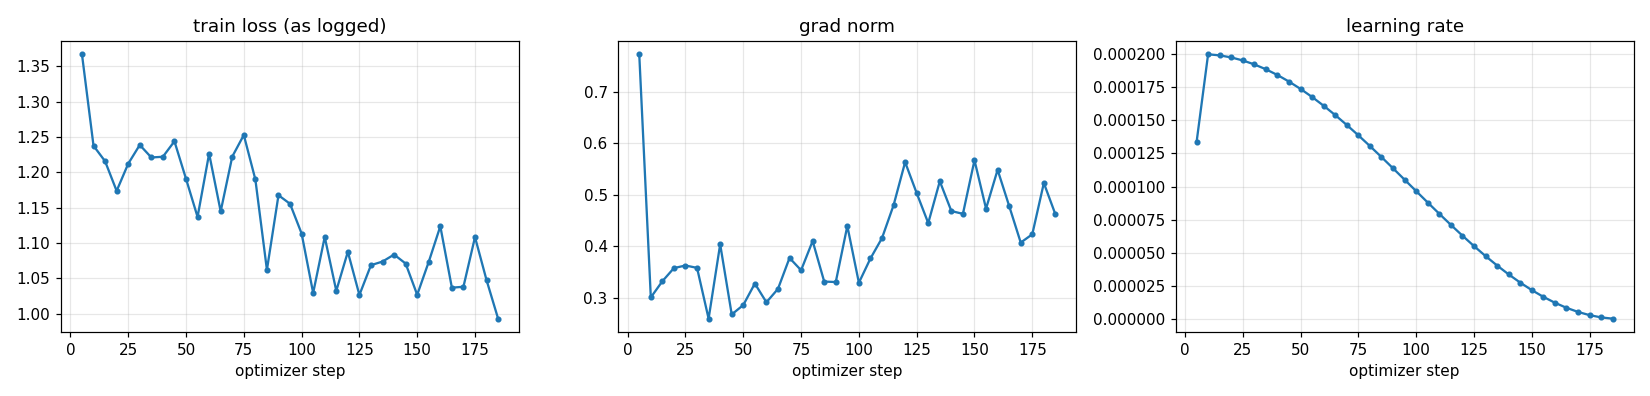

In [12]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

st, rc = K.bg_status("soup_train")
ad = K.find_adapter(K.SOUP_RUN)
if ad is not None and rc == 0:
    K.set_path("adapter", ad); K.set_path("train_root", K.SOUP_RUN); K.set_path("train_backend", "soup")
    K.set_path("train_cmd_name", "soup_train")
else:
    print(f"Soup training produced no adapter (status={st}, rc={rc}). Read logs/cmd/soup_train.log, then run the FALLBACK cell.")
root = K.paths().get("train_root") or K.SOUP_RUN
h = K.training_history(root); s = K.summarize_history(h)
K.write_json(K.OUT / "train_history.json", h); K.write_json(K.OUT / "train_summary.json", s)
png = K.plot_history(h, K.OUT / "loss_curve.png")
print(json.dumps(s, indent=1))
print("peak:", json.dumps(K.read_json(K.LOGS / "peak_soup_train.json"), indent=1))
print("\n--- lines of interest from the Soup training log ---\n" + "\n".join(K.grep_log(K.paths().get("train_cmd_name") or "soup_train")[:80]))
if png:
    from IPython.display import Image, display; display(Image(str(png)))

#### FALLBACK (only if Soup training failed): transformers + peft, same hyper-parameters
Own loop: fp16 autocast + GradScaler (skipped steps are counted), loss normalised over the whole accumulation window, labels only on
answer tokens incl. `<|im_end|>` (same `encode_example` as the evaluation). Runs automatically only when no Soup adapter exists.

In [13]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

USE_FALLBACK = K.paths().get("adapter") is None
if USE_FALLBACK:
    a = K.peak_cmd("logs/peak_fallback_train.json", script=K.WORK / "kit_common.py",
                   script_args=["fallback-train", "--train", "data/train.jsonl", "--out", K.rel(K.FALLBACK_RUN), "--hp", json.dumps(K.HP)])
    K.run_bg("fallback_train", a, timeout_s=3 * 3600, peak_json="logs/peak_fallback_train.json")
    rc = K.wait_bg("fallback_train", max_wait_s=MAX_WAIT_S)
    if rc == 0 and K.find_adapter(K.FALLBACK_RUN):
        K.set_path("adapter", K.find_adapter(K.FALLBACK_RUN)); K.set_path("train_root", K.FALLBACK_RUN)
        K.set_path("train_backend", "fallback: transformers+peft"); K.set_path("train_cmd_name", "fallback_train")
        h = K.training_history(K.FALLBACK_RUN); K.write_json(K.OUT / "train_history.json", h)
        K.write_json(K.OUT / "train_summary.json", K.summarize_history(h)); K.plot_history(h, K.OUT / "loss_curve.png")
        print(json.dumps(K.summarize_history(h), indent=1))
    else:
        print("rc =", rc, "(None = still running -> re-run this cell)")
else:
    print("Soup adapter present -> fallback not needed:", K.paths().get("adapter"))

Soup adapter present -> fallback not needed: /content/soup-task/outputs/soup_run


## 5. Merge and 4-bit quantization (≈6–10 min)
* `soup merge` → `outputs/merged` (fp16). In the v0.75 source the merge loads the base with `device_map="cpu"`, so its VRAM peak
  should be ≈0 and its cost is host RAM: compare with the budget.
* `soup merge --save-format 4bit` → `outputs/merged_4bit`: Soup's bitsandbytes-NF4 path (CPU merge → fp16 staged on disk → reload
  with a `BitsAndBytesConfig` on the GPU → save). `soup quantize` only offers gguf/onnx/tensorrt; a GGUF export needs a llama.cpp
  build and its own evaluation runtime, so it is out of scope here and said so in the report.

In [14]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

ad = K.paths().get("adapter"); assert ad, "no adapter: finish §4 first"
if not ((K.MERGED / "config.json").exists() and any(K.MERGED.glob("*.safetensors"))):
    K.run_bg("soup_merge", K.peak_cmd("logs/peak_soup_merge.json", soup_args=K.soup_merge_args(ad, K.MERGED)),
             restart=K.bg_status("soup_merge")[0] == "done", timeout_s=3600, peak_json="logs/peak_soup_merge.json")
    rc = K.wait_bg("soup_merge", max_wait_s=MAX_WAIT_S)
    print("rc =", rc)
ok = (K.MERGED / "config.json").exists() and any(K.MERGED.glob("*.safetensors"))
K.set_path("merged", K.MERGED if ok else None)
print("merged ok:", ok, "| peak:", K.read_json(K.LOGS / "peak_soup_merge.json"))
print("files:", sorted(p.name for p in K.MERGED.iterdir()) if K.MERGED.exists() else None)

2026-11-11T18:08:02.012 INFO [soup_merge] started pid=8080: /usr/bin/python3 /content/soup-task/kit_common.py peak --json logs/peak_soup_merge.json --soup -- merge --adapter outputs/soup_run --output outputs/merged --dtype float16


   2026-11-11T18:08:02.116+00:00 | $ /usr/bin/python3 /content/soup-task/kit_common.py peak --json logs/peak_soup_merge.json --soup -- merge --adapter outputs/soup_run --output outputs/merged --dtype float16


   2026-11-11T18:08:02.848+00:00 | ╭───────────────────────────────────────────────────────────────────────────────────────────── Merge Plan ─────────────────────────────────────────────────────────────────────────────────────────────╮
   2026-11-11T18:08:02.848+00:00 | │ Adapter: outputs/soup_run                                                                                                                                                                            │
   2026-11-11T18:08:02.848+00:00 | │ Base:    Qwen/Qwen2.5-1.5B-Instruct                                                                                                                                                                  │
   2026-11-11T18:08:02.848+00:00 | │ Output:  outputs/merged                                                                                                                                                                              │
   2026-11-11T18:08:02.848+00:00 | │ Dtype:   float16   

   2026-11-11T18:08:11.395+00:00 | Loading base model: Qwen/Qwen2.5-1.5B-Instruct...
   2026-11-11T18:08:11.396+00:00 | Base revision: 989aa7980e4cf806f80c7fef2b1adb7bc71aa306 (recorded run)


   2026-11-11T18:08:21.297+00:00 | Loading LoRA adapter: outputs/soup_run...
   2026-11-11T18:08:22.446+00:00 | Merging weights...


   2026-11-11T18:08:35.765+00:00 | Saving merged model to outputs/merged...


   2026-11-11T18:09:09.518+00:00 | Saving tokenizer...
   2026-11-11T18:09:10.675+00:00 | ╭────────────────────────────────────────────────────────────────────────────────────────── Merge Complete! ───────────────────────────────────────────────────────────────────────────────────────────╮
   2026-11-11T18:09:10.675+00:00 | │ Output: outputs/merged                                                                                                                                                                               │
   2026-11-11T18:09:10.675+00:00 | │ Size:   2.9 GB                                                                                                                                                                                       │
   2026-11-11T18:09:10.675+00:00 | │                                                                                                                                                                                                      │
 

rc = 0
2026-11-11T18:09:15.290 INFO paths.json: merged = /content/soup-task/outputs/merged


merged ok: True | peak: {'argv': ['merge', '--adapter', 'outputs/soup_run', '--output', 'outputs/merged', '--dtype', 'float16'], 'soup': True, 'script': None, 'started': '2026-11-11T18:08:02.201+00:00', 'finished': '2026-11-11T18:09:10.897+00:00', 'wall_s': 68.7, 'pid': 8081, 'ru_maxrss_gib': 6.598232269287109, 'ru_maxrss_children_gib': 0.46285247802734375, 'cuda_initialized': True, 'device': 'Tesla T4', 'torch_max_allocated_gib': 0.06878662109375, 'torch_max_reserved_gib': 0.0703125}
files: ['chat_template.jinja', 'config.json', 'generation_config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']


In [15]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

# FALLBACK merge (only if soup merge failed): PEFT merge_and_unload on CPU in fp16, same as Soup's code path
if K.paths().get("merged") is None:
    a = K.peak_cmd("logs/peak_fallback_merge.json", script=K.WORK / "kit_common.py",
                   script_args=["fallback-merge", "--adapter", K.paths()["adapter"], "--out", K.rel(K.MERGED), "--device", "cpu"])
    K.run_bg("fallback_merge", a, timeout_s=3600, peak_json="logs/peak_fallback_merge.json")
    rc = K.wait_bg("fallback_merge", max_wait_s=MAX_WAIT_S)
    if rc == 0:
        K.set_path("merged", K.MERGED); K.set_path("merge_backend", "fallback")
else:
    print("merged present -> fallback not needed")

merged present -> fallback not needed


In [16]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

caps = K.soup_caps(); ad = K.paths().get("adapter")
if not (K.MERGED_4BIT / "config.json").exists() and caps.get("merge_has_save_format"):
    K.run_bg("soup_quantize_4bit", K.peak_cmd("logs/peak_soup_quantize_4bit.json",
             soup_args=K.soup_merge_args(ad, K.MERGED_4BIT, ["--save-format", "4bit"])),
             restart=K.bg_status("soup_quantize_4bit")[0] == "done", timeout_s=3600, peak_json="logs/peak_soup_quantize_4bit.json")
    rc = K.wait_bg("soup_quantize_4bit", max_wait_s=MAX_WAIT_S)
    print("rc =", rc)
qc = (K.read_json(K.MERGED_4BIT / "config.json", {}) or {}).get("quantization_config")
K.set_path("merged_4bit", K.MERGED_4BIT if qc else None)
print("4-bit quantization_config:", json.dumps(qc, indent=1))
print("peak:", K.read_json(K.LOGS / "peak_soup_quantize_4bit.json"))

2026-11-11T18:09:15.316 INFO [soup_quantize_4bit] started pid=8384: /usr/bin/python3 /content/soup-task/kit_common.py peak --json logs/peak_soup_quantize_4bit.json --soup -- merge --adapter outputs/soup_run --output outputs/merged_4bit --dtype float16 --save-format 4bit


   2026-11-11T18:09:15.447+00:00 | $ /usr/bin/python3 /content/soup-task/kit_common.py peak --json logs/peak_soup_quantize_4bit.json --soup -- merge --adapter outputs/soup_run --output outputs/merged_4bit --dtype float16 --save-format 4bit


   2026-11-11T18:09:16.166+00:00 | ╭───────────────────────────────────────────────────────────────────────────────────────────── Merge Plan ─────────────────────────────────────────────────────────────────────────────────────────────╮
   2026-11-11T18:09:16.166+00:00 | │ Adapter: outputs/soup_run                                                                                                                                                                            │
   2026-11-11T18:09:16.166+00:00 | │ Base:    Qwen/Qwen2.5-1.5B-Instruct                                                                                                                                                                  │
   2026-11-11T18:09:16.166+00:00 | │ Output:  outputs/merged_4bit                                                                                                                                                                         │
   2026-11-11T18:09:16.166+00:00 | │ Dtype:   float16   

   2026-11-11T18:09:25.388+00:00 | Loading base model: Qwen/Qwen2.5-1.5B-Instruct...
   2026-11-11T18:09:25.391+00:00 | Base revision: 989aa7980e4cf806f80c7fef2b1adb7bc71aa306 (recorded run)


   2026-11-11T18:09:34.590+00:00 | Loading LoRA adapter: outputs/soup_run...
   2026-11-11T18:09:35.389+00:00 | Merging weights...


   2026-11-11T18:09:48.848+00:00 | Staging fp16 merge in .soup_4bit_merge_k87lff4a...


   2026-11-11T18:10:31.067+00:00 | Re-loading + saving BNB-4bit merge (4bit) to outputs/merged_4bit...


   2026-11-11T18:10:44.608+00:00 | ╭────────────────────────────────────────────────────────────────────────────────────────── Merge Complete! ───────────────────────────────────────────────────────────────────────────────────────────╮
   2026-11-11T18:10:44.608+00:00 | │ Output: outputs/merged_4bit                                                                                                                                                                          │
   2026-11-11T18:10:44.608+00:00 | │ Size:   1.1 GB                                                                                                                                                                                       │
   2026-11-11T18:10:44.608+00:00 | │                                                                                                                                                                                                      │
   2026-11-11T18:10:44.608+00:00 | │ Next steps:        

rc = 0
2026-11-11T18:10:58.574 INFO paths.json: merged_4bit = /content/soup-task/outputs/merged_4bit


4-bit quantization_config: {
 "_load_in_4bit": true,
 "_load_in_8bit": false,
 "bnb_4bit_compute_dtype": "float16",
 "bnb_4bit_quant_storage": "uint8",
 "bnb_4bit_quant_type": "nf4",
 "bnb_4bit_use_double_quant": true,
 "llm_int8_enable_fp32_cpu_offload": false,
 "llm_int8_has_fp16_weight": false,
 "llm_int8_skip_modules": null,
 "llm_int8_threshold": 6.0,
 "load_in_4bit": true,
 "load_in_8bit": false,
 "quant_method": "bitsandbytes"
}
peak: {'argv': ['merge', '--adapter', 'outputs/soup_run', '--output', 'outputs/merged_4bit', '--dtype', 'float16', '--save-format', '4bit'], 'soup': True, 'script': None, 'started': '2026-11-11T18:09:15.537+00:00', 'finished': '2026-11-11T18:10:44.768+00:00', 'wall_s': 89.2, 'pid': 8389, 'ru_maxrss_gib': 6.597469329833984, 'ru_maxrss_children_gib': 0.4629478454589844, 'cuda_initialized': True, 'device': 'Tesla T4', 'torch_max_allocated_gib': 1.0989656448364258, 'torch_max_reserved_gib': 1.14453125}


In [17]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

# FALLBACK 4-bit (only if Soup's 4-bit path failed): BitsAndBytesConfig nf4 + double quant, fp16 compute, from the merged fp16
if K.paths().get("merged_4bit") is None and K.paths().get("merged"):
    a = K.peak_cmd("logs/peak_fallback_quantize.json", script=K.WORK / "kit_common.py",
                   script_args=["fallback-quantize", "--merged", K.paths()["merged"], "--out", K.rel(K.MERGED_4BIT)])
    K.run_bg("fallback_quantize", a, timeout_s=3600, peak_json="logs/peak_fallback_quantize.json")
    rc = K.wait_bg("fallback_quantize", max_wait_s=MAX_WAIT_S)
    if rc == 0:
        K.set_path("merged_4bit", K.MERGED_4BIT); K.set_path("quant_backend", "fallback")
else:
    print("4-bit present (or no merged model) -> fallback not run")

4-bit present (or no merged model) -> fallback not run


## 6. Negative control (≈5–8 min)
Same pipeline (Soup train → Soup merge), but **lr = 1e-9** on 64 rows for 1 epoch: a run that "finishes successfully" without
meaningfully changing the model. Soup's schema rejects `lr: 0` (`lr > 0`): §3b's `cfg_lr_zero` dry-run records that. The verification
in §7 must flag this control as **untrained**; if it does not, the check is worthless.

In [18]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

backend = K.paths().get("train_backend") or "soup"
if K.find_adapter(K.NC_RUN) is None:
    if backend == "soup":
        K.run_bg("soup_nc_train", K.peak_cmd("logs/peak_soup_nc_train.json", soup_args=K.soup_train_args("soup_nc.yaml")),
                 restart=K.bg_status("soup_nc_train")[0] == "done", timeout_s=3600, peak_json="logs/peak_soup_nc_train.json")
        rc = K.wait_bg("soup_nc_train", max_wait_s=MAX_WAIT_S)
    else:
        a = K.peak_cmd("logs/peak_fallback_nc_train.json", script=K.WORK / "kit_common.py",
                       script_args=["fallback-train", "--train", "data/nc_train.jsonl", "--out", K.rel(K.NC_RUN), "--hp", json.dumps(K.NC_HP)])
        K.run_bg("fallback_nc_train", a, timeout_s=3600, peak_json="logs/peak_fallback_nc_train.json")
        rc = K.wait_bg("fallback_nc_train", max_wait_s=MAX_WAIT_S)
nc = K.find_adapter(K.NC_RUN)
K.set_path("nc_adapter", nc)
if nc is not None and not (K.NC_MERGED / "config.json").exists():
    if (K.paths().get("merge_backend") or "soup") == "soup":
        K.run_bg("soup_nc_merge", K.peak_cmd("logs/peak_soup_nc_merge.json", soup_args=K.soup_merge_args(nc, K.NC_MERGED)),
                 restart=K.bg_status("soup_nc_merge")[0] == "done", timeout_s=3600, peak_json="logs/peak_soup_nc_merge.json")
        K.wait_bg("soup_nc_merge", max_wait_s=MAX_WAIT_S)
    else:
        a = K.peak_cmd("logs/peak_fallback_nc_merge.json", script=K.WORK / "kit_common.py",
                       script_args=["fallback-merge", "--adapter", str(nc), "--out", K.rel(K.NC_MERGED), "--device", "cpu"])
        K.run_bg("fallback_nc_merge", a, timeout_s=3600); K.wait_bg("fallback_nc_merge", max_wait_s=MAX_WAIT_S)
K.set_path("nc_merged", K.NC_MERGED if (K.NC_MERGED / "config.json").exists() else None)
h = K.training_history(K.NC_RUN); K.write_json(K.OUT / "nc_train_summary.json", K.summarize_history(h))
print("NC adapter:", nc, "| NC merged:", K.paths().get("nc_merged"))
print("NC training summary (it 'finished fine'):", json.dumps(K.summarize_history(h), indent=1))

2026-11-11T18:10:58.603 INFO [soup_nc_train] started pid=8815: /usr/bin/python3 /content/soup-task/kit_common.py peak --json logs/peak_soup_nc_train.json --soup -- train --config soup_nc.yaml --yes


   2026-11-11T18:10:58.704+00:00 | $ /usr/bin/python3 /content/soup-task/kit_common.py peak --json logs/peak_soup_nc_train.json --soup -- train --config soup_nc.yaml --yes


   2026-11-11T18:10:59.468+00:00 | Loading config from soup_nc.yaml...


   2026-11-11T18:11:02.022+00:00 | ╭─────────────────────────────────────────────────────────────────────────────────────────── Training Setup ───────────────────────────────────────────────────────────────────────────────────────────╮
   2026-11-11T18:11:02.022+00:00 | │ Device:  Tesla T4                                                                                                                                                                                    │
   2026-11-11T18:11:02.022+00:00 | │ Memory:  14.6 GB                                                                                                                                                                                     │
   2026-11-11T18:11:02.022+00:00 | │ Model:   Qwen/Qwen2.5-1.5B-Instruct                                                                                                                                                                  │
   2026-11-11T18:11:02.022+00:00 | │ Task:    sft       

   2026-11-11T18:11:14.386+00:00 | Loading tokenizer: Qwen/Qwen2.5-1.5B-Instruct
   2026-11-11T18:11:15.717+00:00 | Loading model: Qwen/Qwen2.5-1.5B-Instruct


   2026-11-11T18:11:25.001+00:00 | LoRA applied: 18,464,768 trainable / 1,562,179,072 total (1.18%)


... (8 outputs left out)

   2026-11-11T18:12:24.424+00:00 | Saving merged model to outputs/nc_merged...


   2026-11-11T18:13:17.653+00:00 | Saving tokenizer...
   2026-11-11T18:13:18.786+00:00 | ╭────────────────────────────────────────────────────────────────────────────────────────── Merge Complete! ───────────────────────────────────────────────────────────────────────────────────────────╮
   2026-11-11T18:13:18.786+00:00 | │ Output: outputs/nc_merged                                                                                                                                                                            │
   2026-11-11T18:13:18.786+00:00 | │ Size:   2.9 GB                                                                                                                                                                                       │
   2026-11-11T18:13:18.786+00:00 | │                                                                                                                                                                                                      │
 

2026-11-11T18:13:25.145 INFO paths.json: nc_merged = /content/soup-task/outputs/nc_merged


NC adapter: /content/soup-task/outputs/nc_run | NC merged: /content/soup-task/outputs/nc_merged
NC training summary (it 'finished fine'): {
 "source": "outputs/nc_run/checkpoint-4/trainer_state.json",
 "global_step": 4,
 "max_steps": 4,
 "n_logged": 0,
 "first_loss": null,
 "last_loss": null,
 "min_loss": null,
 "max_grad_norm": null,
 "nonfinite_entries": 0,
 "train_runtime": null,
 "skipped_steps_fp16": null
}


## 7. Verification: is the model real? (≈10–15 min)
`verify_trained.py` (standalone, does not import Soup) loads **base, base+adapter (unmerged), base+control, merged fp16, the 4-bit
artifact and the base quantized with the same 4-bit config** and evaluates them in lockstep on the same 200 held-out rows with the
same chat template:

* **A** adapter file read directly: `‖lora_B‖` (B is zero at init), modules found vs 28 × 7 expected, every module maps onto a base
  weight, file tensors == what PEFT loaded, predicted fp16 rounding loss of the update.
* **B** merged weights == fp16(base + α/r · B·A) computed independently; non-LoRA parameters bit-identical; relative ΔW per module type.
* **C** held-out NLL on answer tokens only, paired bootstrap 95 % CI; 4-bit gain measured against the **4-bit base** (like with like).
* **D** KL + top-1 agreement of next-token distributions: merged↔base (did it change?), adapter↔merged (did the merge preserve it?),
  merged↔4-bit (quant fidelity), base↔base-4-bit (quantization noise floor to compare the training effect against).
* **Q** 4-bit codes: artifact == quantize(merged) and ≠ quantize(base). **E** greedy generations side by side, EOS, language,
  repetition, inf/NaN logits. **T** tokenizer/template/generation_config consistency.

Exit code 2 means "verdict: not trained", not a crash.

In [19]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

P = K.paths()
assert P.get("adapter") and P.get("merged"), "need adapter + merged (sections 4-5)"
args = ["--base", K.MODEL_ID, "--adapter", P["adapter"], "--merged", P["merged"], "--eval-data", "data/eval.jsonl",
        "--train-data", "data/train.jsonl", "--prompts", "data/probe_prompts.jsonl", "--out-dir", K.rel(K.VERIFY_DIR),
        "--max-length", str(K.MAX_LEN)]
if P.get("merged_4bit"): args += ["--quant4", P["merged_4bit"]]
if P.get("nc_adapter"): args += ["--control-adapter", P["nc_adapter"]]
if P.get("nc_merged"): args += ["--control-merged", P["nc_merged"]]
K.run_bg("verify", K.peak_cmd("logs/peak_verify.json", script=K.WORK / "verify_trained.py", script_args=args),
         timeout_s=2 * 3600, peak_json="logs/peak_verify.json")
rc = K.wait_bg("verify", max_wait_s=MAX_WAIT_S)
print("rc =", rc, "(0 = trained, 2 = NOT trained, None = still running)")
if (K.VERIFY_DIR / "verify_summary.txt").exists():
    print(open(K.VERIFY_DIR / "verify_summary.txt").read())

2026-11-11T18:13:25.174 INFO [verify] started pid=9441: /usr/bin/python3 /content/soup-task/kit_common.py peak --json logs/peak_verify.json --script /content/soup-task/verify_trained.py -- --base Qwen/Qwen2.5-1.5B-Instruct --adapter /content/soup-task/outputs/soup_run --merged /content/soup-task/outputs/merged --eval-data data/eval.jsonl --train-data data/train.jsonl --prompts data/probe_prompts.jsonl --out-dir outputs/verify --max-length 1024 --quant4 /content/soup-task/outputs/merged_4bit --control-adapter /content/soup-task/outputs/nc_run --control-merged /content/soup-task/outputs/nc_merged


   2026-11-11T18:13:25.318+00:00 | $ /usr/bin/python3 /content/soup-task/kit_common.py peak --json logs/peak_verify.json --script /content/soup-task/verify_trained.py -- --base Qwen/Qwen2.5-1.5B-Instruct --adapter /content/soup-task/outputs/soup_run --merged /content/soup-task/outputs/merged --eval-data data/eval.jsonl --train-data data/train.jsonl --prompts data/probe_prompts.jsonl --out-dir outputs


   2026-11-11T18:13:25.550+00:00 | 2026-11-11T18:13:25.549+00:00 [verify] START argv=['--base', 'Qwen/Qwen2.5-1.5B-Instruct', '--adapter', '/content/soup-task/outputs/soup_run', '--merged', '/content/soup-task/outputs/merged', '--eval-data', 'data/eval.jsonl', '--train-data', 'data/train.jsonl', '--prompts', 'data/probe_prompts.jsonl', '--out-dir', 'outputs/verify', '--max-length', '1024', '--quant4'


   2026-11-11T18:14:40.538+00:00 | 2026-11-11T18:14:40.538+00:00 [verify] CHECK A1         PASS  LoRA modules present and mapped onto base weights: value={'n': 196, 'expected': 196, 'unmapped': 0} threshold=n == expected, unmapped == 0
   2026-11-11T18:14:40.538+00:00 | 2026-11-11T18:14:40.538+00:00 [verify] CHECK A2         PASS  lora_B moved away from its zero init: value={'frac_modules': 1.0, 'B_fro': {'min': 0.10316880792379379, 'median': 0.29907986521720886, 'max': 0.8570602536201477, 'n': 196}, 'n_exact_zero': 0} threshold=>= 0.9 of modules with ||B||_F > 0.001
   2026-11-11T18:14:40.538+00:00 | 2026-11-11T18:14:40.538+00:00 [verify] CHECK B4         PASS  Predicted fp16 rounding loss of the update at merge: value={'median': 0.025239163090733416, 'frac_elements_unchanged_median': 0.0281982421875} threshold=median <= 0.3 (WARN only)
   2026-11-11T18:14:40.538+00:00 | 2026-11-11T18:14:40.538+00:00 [verify] CHECK A1_control PASS  LoRA modules present and mapped onto base weights: va

   2026-11-11T18:15:00.671+00:00 | 2026-11-11T18:15:00.670+00:00 [verify] CHECK B1         PASS  Merged weights differ from base (median relative delta): value={'median_rel_delta': 0.00821162525672935, 'per_type': {'down_proj': {'median_rel_delta': 0.004333685133944776, 'max_rel_delta': 0.005115222002878221, 'n': 28}, 'gate_proj': {'median_rel_delta': 0.008848481911546347, 'max_rel_delta': 0.01272387
   2026-11-11T18:15:00.671+00:00 | 2026-11-11T18:15:00.671+00:00 [verify] CHECK B2         PASS  Merged == fp16(base + scale*B@A), computed independently: value={'max_err_vs_reference': 0.0, 'n_modules': 196, 'n_meaningful': 196, 'broken_modules': [], 'min_exact_match_frac': 1.0} threshold=max <= 0.05 (relative to the size of the update)
   2026-11-11T18:15:00.671+00:00 | 2026-11-11T18:15:00.671+00:00 [verify] CHECK B3         PASS  Non-LoRA parameters untouched by the merge: value={'max_abs_diff': 0.0, 'n_compared': 142, 'offenders': []} threshold=max abs diff <= 0.0
   2026-11-11T18:15:0

   2026-11-11T18:15:10.587+00:00 | 2026-11-11T18:15:10.587+00:00 [verify] CHECK Q1         PASS  4-bit artifact == quantize(merged fp16): value={'median': 0.0, 'max': 0.0} threshold=max <= 1e-06
   2026-11-11T18:15:10.587+00:00 | 2026-11-11T18:15:10.587+00:00 [verify] CHECK Q2         PASS  Fine-tune changed 4-bit codes (quantize(merged) != quantize(base)): value={'mean_frac_weights_changed': 0.6200011123199852} threshold=>= 0.0001
   2026-11-11T18:15:10.588+00:00 | 2026-11-11T18:15:10.588+00:00 [verify] eval pass over 200 examples, views=['base', 'adapter', 'control', 'merged', 'merged_4bit', 'base_4bit'], pairs=[('merged', 'base'), ('adapter', 'merged'), ('merged', 'merged_4bit'), ('base', 'base_4bit'), ('merged_4bit', 'base_4bit'), ('control', 'base')]


... (13 outputs left out)

   2026-11-11T18:19:03.622+00:00 | 2026-11-11T18:19:03.622+00:00 [verify] generated 12 outputs for view=merged


   2026-11-11T18:19:26.894+00:00 | 2026-11-11T18:19:26.893+00:00 [verify] generated 12 outputs for view=merged_4bit
   2026-11-11T18:19:26.897+00:00 | 2026-11-11T18:19:26.897+00:00 [verify] CHECK E1_merged  WARN  Generations of merged: stop at EOS, Russian, not degenerate: value={'eos_rate': 0.6666666666666666, 'median_new_tokens': 147.0, 'frac_cyrillic_ok': 1.0, 'max_rep4': 0.447, 'n': 12} threshold=eos_rate >= 0.9, >=90% prompts cyrillic >= 0.6, rep4 <= 0.3 (WARN only: read generations.md yourself)
   2026-11-11T18:19:26.898+00:00 | 2026-11-11T18:19:26.898+00:00 [verify] CHECK E1_merged_4bit WARN  Generations of merged_4bit: stop at EOS, Russian, not degenerate: value={'eos_rate': 0.5833333333333334, 'median_new_tokens': 165.5, 'frac_cyrillic_ok': 1.0, 'max_rep4': 0.635, 'n': 12} threshold=eos_rate >= 0.9, >=90% prompts cyrillic >= 0.6, rep4 <= 0.3 (WARN only: read generations.md yourself)
   2026-11-11T18:19:26.898+00:00 | 2026-11-11T18:19:26.898+00:00 [verify] CHECK E3         PASS

   ... 46 lines not shown (full log: logs/cmd/verify.log)
   2026-11-11T18:19:44.858+00:00 |   [PASS] D1          Merged behaves like base+adapter (KL, top-1)
   2026-11-11T18:19:44.858+00:00 |   [PASS] D2          Merged changed next-token distributions vs base (KL)
   2026-11-11T18:19:44.859+00:00 |   [FAIL] D2_control  Control changed distributions vs base (expected FAIL)
   2026-11-11T18:19:44.859+00:00 |   [PASS] D3          4-bit fidelity to merged fp16 (KL, top-1)
   2026-11-11T18:19:44.859+00:00 |   [PASS] E2          No inf/NaN logits (fp16 overflow on T4)
   2026-11-11T18:19:44.859+00:00 |   [WARN] E1_merged   Generations of merged: stop at EOS, Russian, not degenerate
   2026-11-11T18:19:44.859+00:00 |   [WARN] E1_merged_4bit Generations of merged_4bit: stop at EOS, Russian, not degenerate
   2026-11-11T18:19:44.859+00:00 |   [PASS] E3          Greedy outputs changed vs base on at least one probe
   2026-11-11T18:19:44.859+00:00 |   [PASS] T1          Tokenizer + chat templa

rc = 0 (0 = trained, 2 = NOT trained, None = still running)
verify_trained.py summary  (2026-11-11T18:19:44.853+00:00)
views: base, adapter, control, merged, merged_4bit, base_4bit

Held-out answer-token NLL (nats/token), 95% bootstrap CI over examples:
  base         nll=1.3034 ppl=3.682 ci95=[1.2560, 1.3550] tokens=42756 nonfinite=0
  adapter      nll=1.2195 ppl=3.385 ci95=[1.1725, 1.2698] tokens=42756 nonfinite=0
  control      nll=1.3034 ppl=3.682 ci95=[1.2560, 1.3550] tokens=42756 nonfinite=0
  merged       nll=1.2195 ppl=3.385 ci95=[1.1725, 1.2698] tokens=42756 nonfinite=0
  merged_4bit  nll=1.2827 ppl=3.606 ci95=[1.2342, 1.3358] tokens=42756 nonfinite=0
  base_4bit    nll=1.3564 ppl=3.882 ci95=[1.3072, 1.4098] tokens=42756 nonfinite=0
Paired differences (positive = second model has lower NLL):
  base-merged                +0.0840  ci95=[+0.0760, +0.0920]
  base-adapter               +0.0839  ci95=[+0.0760, +0.0920]
  base-control               -0.0000  ci95=[-0.0000, +0.0000]
  

### 7.1 Second negative control (NC2): "the adapter is fine but the merge did not apply it" (≈4 min)
Runs the same script with `--merged` pointing at the **base model**. Expected: A-checks PASS (the adapter is real) while B1/B2/C1/D1
FAIL. This demonstrates that the merge checks catch a merge that silently produced the base.

In [20]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

P = K.paths()
args = ["--base", K.MODEL_ID, "--adapter", P["adapter"], "--merged", K.MODEL_ID, "--eval-data", "data/eval.jsonl",
        "--out-dir", K.rel(K.VERIFY_NC2_DIR), "--max-eval", "100", "--skip-generations", "--max-length", str(K.MAX_LEN)]
K.run_bg("verify_nc2", K.peak_cmd("logs/peak_verify_nc2.json", script=K.WORK / "verify_trained.py", script_args=args), timeout_s=3600)
rc = K.wait_bg("verify_nc2", max_wait_s=MAX_WAIT_S)
if (K.VERIFY_NC2_DIR / "verify_summary.txt").exists():
    print(open(K.VERIFY_NC2_DIR / "verify_summary.txt").read())

2026-11-11T18:19:53.483 INFO [verify_nc2] started pid=11056: /usr/bin/python3 /content/soup-task/kit_common.py peak --json logs/peak_verify_nc2.json --script /content/soup-task/verify_trained.py -- --base Qwen/Qwen2.5-1.5B-Instruct --adapter /content/soup-task/outputs/soup_run --merged Qwen/Qwen2.5-1.5B-Instruct --eval-data data/eval.jsonl --out-dir outputs/verify_nc2 --max-eval 100 --skip-generations --max-length 1024


   2026-11-11T18:19:53.579+00:00 | $ /usr/bin/python3 /content/soup-task/kit_common.py peak --json logs/peak_verify_nc2.json --script /content/soup-task/verify_trained.py -- --base Qwen/Qwen2.5-1.5B-Instruct --adapter /content/soup-task/outputs/soup_run --merged Qwen/Qwen2.5-1.5B-Instruct --eval-data data/eval.jsonl --out-dir outputs/verify_nc2 --max-eval 100 --skip-generations --max-length 1024


   2026-11-11T18:19:53.777+00:00 | 2026-11-11T18:19:53.776+00:00 [verify] START argv=['--base', 'Qwen/Qwen2.5-1.5B-Instruct', '--adapter', '/content/soup-task/outputs/soup_run', '--merged', 'Qwen/Qwen2.5-1.5B-Instruct', '--eval-data', 'data/eval.jsonl', '--out-dir', 'outputs/verify_nc2', '--max-eval', '100', '--skip-generations', '--max-length', '1024']


   2026-11-11T18:20:36.281+00:00 | 2026-11-11T18:20:36.281+00:00 [verify] CHECK A1         PASS  LoRA modules present and mapped onto base weights: value={'n': 196, 'expected': 196, 'unmapped': 0} threshold=n == expected, unmapped == 0
   2026-11-11T18:20:36.281+00:00 | 2026-11-11T18:20:36.281+00:00 [verify] CHECK A2         PASS  lora_B moved away from its zero init: value={'frac_modules': 1.0, 'B_fro': {'min': 0.10316880792379379, 'median': 0.29907986521720886, 'max': 0.8570602536201477, 'n': 196}, 'n_exact_zero': 0} threshold=>= 0.9 of modules with ||B||_F > 0.001
   2026-11-11T18:20:36.281+00:00 | 2026-11-11T18:20:36.281+00:00 [verify] CHECK B4         PASS  Predicted fp16 rounding loss of the update at merge: value={'median': 0.025239163090733416, 'frac_elements_unchanged_median': 0.0281982421875} threshold=median <= 0.3 (WARN only)


   2026-11-11T18:20:36.814+00:00 | 2026-11-11T18:20:36.814+00:00 [verify] eval: encoded 100/100 rows, skipped={'template_error': 0, 'too_long': 0, 'no_answer_tokens': 0}, prompt-prefix token mismatch=0
   2026-11-11T18:20:36.814+00:00 | 2026-11-11T18:20:36.814+00:00 [verify] loading base (fp16) + adapter(s) as PeftModel
   2026-11-11T18:20:40.151+00:00 | 2026-11-11T18:20:40.151+00:00 [verify] CHECK A3         PASS  Adapter tensors PEFT loaded == tensors in the file: value={'max_abs_diff': 0.0, 'file_modules_not_in_model': 0, 'model_modules_not_in_file': 0, 'examples': []} threshold=0 missing, max diff <= 1e-06
   2026-11-11T18:20:40.151+00:00 | 2026-11-11T18:20:40.151+00:00 [verify] loading merged checkpoint
   2026-11-11T18:20:44.917+00:00 | 2026-11-11T18:20:44.917+00:00 [verify] CHECK B1         FAIL  Merged weights differ from base (median relative delta): value={'median_rel_delta': 0.0, 'per_type': {'down_proj': {'median_rel_delta': 0.0, 'max_rel_delta': 0.0, 'n': 28}, 'gate_proj':

   2026-11-11T18:20:53.193+00:00 | 2026-11-11T18:20:53.193+00:00 [verify] eval: 25/100 examples
   2026-11-11T18:21:00.630+00:00 | 2026-11-11T18:21:00.630+00:00 [verify] eval: 50/100 examples


   ... 22 lines not shown (full log: logs/cmd/verify_nc2.log)
   2026-11-11T18:21:18.131+00:00 |   [PASS] A1          LoRA modules present and mapped onto base weights
   2026-11-11T18:21:18.131+00:00 |   [PASS] A2          lora_B moved away from its zero init
   2026-11-11T18:21:18.132+00:00 |   [PASS] B4          Predicted fp16 rounding loss of the update at merge
   2026-11-11T18:21:18.132+00:00 |   [PASS] A3          Adapter tensors PEFT loaded == tensors in the file
   2026-11-11T18:21:18.132+00:00 |   [FAIL] B1          Merged weights differ from base (median relative delta)
   2026-11-11T18:21:18.132+00:00 |   [FAIL] B2          Merged == fp16(base + scale*B@A), computed independently
   2026-11-11T18:21:18.132+00:00 |   [PASS] B3          Non-LoRA parameters untouched by the merge
   2026-11-11T18:21:18.132+00:00 |   [FAIL] C1          Held-out answer NLL: base - merged (nats/token, paired bootstrap)
   2026-11-11T18:21:18.132+00:00 |   [FAIL] D1          Merged behaves like ba

verify_trained.py summary  (2026-11-11T18:21:18.129+00:00)
views: base, adapter, merged

Held-out answer-token NLL (nats/token), 95% bootstrap CI over examples:
  base         nll=1.2835 ppl=3.609 ci95=[1.2203, 1.3462] tokens=22298 nonfinite=0
  adapter      nll=1.2004 ppl=3.321 ci95=[1.1324, 1.2655] tokens=22298 nonfinite=0
  merged       nll=1.2835 ppl=3.609 ci95=[1.2203, 1.3462] tokens=22298 nonfinite=0
Paired differences (positive = second model has lower NLL):
  base-merged                +0.0000  ci95=[+0.0000, +0.0000]
  base-adapter               +0.0832  ci95=[+0.0731, +0.0944]
KL(p||q) and top-1 agreement on answer positions:
  merged||base               kl=0.00000 top1=1.0000 positions=14806
  adapter||merged            kl=0.12036 top1=0.8660 positions=14806

Checks:
  [PASS] A1          LoRA modules present and mapped onto base weights
  [PASS] A2          lora_B moved away from its zero init
  [PASS] B4          Predicted fp16 rounding loss of the update at merge
  [PASS] 

## 8. `soup ship` (optional, ≈15–25 min)
Live run: base vs merged fp16 with a Russian task-eval (`data/ship_tasks.jsonl`: 30 held-out prompts scored `semantic` against the
reference, 5 Russian facts `contains`, 5 "answer is Russian" `regex`) plus a subset of Soup's bundled leg-2 suites (to fit the T4
time budget; `SHIP_SUITES=""` uses Soup's default). Watch the log for the precision `soup ship` loads models in (v0.75 and
v0.77.2 source: bf16 on CUDA without `--config`; Qwen's shipped `repetition_penalty=1.1` still applies to its greedy decode) and note that it evaluates **merged fp16, not the 4-bit artifact we would ship**.
The second cell feeds **our** held-out metric (geometric-mean token probability `exp(−NLL)`, base fp16 vs 4-bit artifact) plus the
live leg-2 scores into `soup ship --evidence`, to see Soup's decision rule on a metric that actually moves.

In [21]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

RUN_SHIP = True
SHIP_SUITES = "mini_mmlu,mini_instruction"
caps = K.soup_caps(); P = K.paths()
if RUN_SHIP and P.get("merged"):
    args = ["ship", "--base", K.MODEL_ID, "--tuned", P["merged"], "--task-eval", "data/ship_tasks.jsonl",
            "--output", "outputs/ship_verdict.json", "--emit-evidence", "outputs/ship_evidence.json"]
    if caps.get("ship_has_device"): args += ["--device", "cuda"]
    if SHIP_SUITES and caps.get("ship_has_general_suite"): args += ["--general-suite", SHIP_SUITES]
    K.run_bg("soup_ship", K.peak_cmd("logs/peak_soup_ship.json", soup_args=args), timeout_s=90 * 60, peak_json="logs/peak_soup_ship.json")
    rc = K.wait_bg("soup_ship", max_wait_s=MAX_WAIT_S)
    print("rc =", rc, "(0 SHIP, 2 DON'T SHIP, 3 usage error, 1 runtime error, None still running)")
    if rc == 3 and SHIP_SUITES:
        print("usage error -> retrying with Soup's default leg-2 suite")
        args = [a for a in args if a not in ("--general-suite", SHIP_SUITES)]
        K.run_bg("soup_ship_default", K.peak_cmd("logs/peak_soup_ship_default.json", soup_args=args), timeout_s=90 * 60)
        rc = K.wait_bg("soup_ship_default", max_wait_s=MAX_WAIT_S)
    print(json.dumps(K.read_json(K.OUT / "ship_verdict.json"), indent=1, ensure_ascii=False))

2026-11-11T18:21:21.783 INFO [soup_ship] started pid=11439: /usr/bin/python3 /content/soup-task/kit_common.py peak --json logs/peak_soup_ship.json --soup -- ship --base Qwen/Qwen2.5-1.5B-Instruct --tuned /content/soup-task/outputs/merged --task-eval data/ship_tasks.jsonl --output outputs/ship_verdict.json --emit-evidence outputs/ship_evidence.json --device cuda --general-suite mini_mmlu,mini_instruction


   2026-11-11T18:21:21.899+00:00 | $ /usr/bin/python3 /content/soup-task/kit_common.py peak --json logs/peak_soup_ship.json --soup -- ship --base Qwen/Qwen2.5-1.5B-Instruct --tuned /content/soup-task/outputs/merged --task-eval data/ship_tasks.jsonl --output outputs/ship_verdict.json --emit-evidence outputs/ship_evidence.json --device cuda --general-suite mini_mmlu,mini_instruction


   2026-11-11T18:21:23.186+00:00 | Live eval: loading base/tuned at full precision (bfloat16); pass --config to reuse the training run's own quantization.


   2026-11-11T18:26:38.798+00:00 | ╭───────────────────────────────────────────────────────────────────────────────────────────── soup ship ──────────────────────────────────────────────────────────────────────────────────────────────╮
   2026-11-11T18:26:38.798+00:00 | │ DON'T SHIP                                                                                                                                                                                           │
   2026-11-11T18:26:38.798+00:00 | │ Leg 1 task win (metric): 0.2500 -> 0.2500  [no win]                                                                                                                                                  │
   2026-11-11T18:26:38.798+00:00 | │ Judge numerics: bfloat16                                                                                                                                                                             │
   2026-11-11T18:26:38.798+00:00 | │                    

rc = 2 (0 SHIP, 2 DON'T SHIP, 3 usage error, 1 runtime error, None still running)
{
 "decision": "DON'T SHIP",
 "task_win": {
  "mode": "metric",
  "base": 0.25,
  "tuned": 0.25,
  "won": false
 },
 "benchmark_deltas": [
  {
   "name": "mini_instruction",
   "base": 1.0,
   "tuned": 0.9583333333333334,
   "delta": -0.041667,
   "regressed": false
  },
  {
   "name": "mini_mmlu",
   "base": 0.85,
   "tuned": 0.825,
   "delta": -0.025,
   "regressed": false
  }
 ],
 "failed_rule": "task_win",
 "forgetting_threshold": 0.05,
 "soup_version": "0.77.2",
 "noise_floor": null,
 "numerics": "bfloat16"
}


In [22]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

V = K.read_json(K.VERIFY_DIR / "verify_results.json", {}) or {}
H = V.get("heldout") or {}
if "base" in H:
    tuned = "merged_4bit" if "merged_4bit" in H else "merged"
    live = K.read_json(K.OUT / "ship_evidence.json", {}) or {}
    ev = {"task": {"mode": "metric", "base": math.exp(-H["base"]["nll_per_token"]), "tuned": math.exp(-H[tuned]["nll_per_token"])},
          "benchmarks": live.get("benchmarks", {})}
    K.write_json(K.OUT / "ship_evidence_custom.json", ev)
    print("evidence (computed from verify_results.json, tuned =", tuned, "):", json.dumps(ev, indent=1))
    rc, out = K.run_cmd("soup_ship_offline", ["soup", "ship", "--evidence", "outputs/ship_evidence_custom.json",
                                              "--output", "outputs/ship_verdict_offline.json"], timeout_s=300, quiet=True)
    print(f"rc={rc}\n" + out[-3000:])
else:
    print("verification results missing: run §7 first")

evidence (computed from verify_results.json, tuned = merged_4bit ): {
 "task": {
  "mode": "metric",
  "base": 0.2716031032791081,
  "tuned": 0.2772927389190789
 },
 "benchmarks": {
  "mini_instruction": {
   "base": 1.0,
   "tuned": 0.9583333333333334
  },
  "mini_mmlu": {
   "base": 0.85,
   "tuned": 0.825
  }
 }
}
2026-11-11T18:26:50.076 INFO [soup_ship_offline] started pid=12814: soup ship --evidence outputs/ship_evidence_custom.json --output outputs/ship_verdict_offline.json


2026-11-11T18:26:51.399 INFO [soup_ship_offline] finished rc=0


rc=0
───────────────── soup ship ──────────────────────────────────────────────────────────────────────────────────────────────╮
│ SHIP                                                                                                                                                                                                 │
│ Leg 1 task win (metric): 0.2716 -> 0.2773  [won]                                                                                                                                                     │
│ Judge numerics: unstamped                                                                                                                                                                            │
│                                                                                                                                                                                                      │
│ Leg 2 general suite (threshold 5.00%)                            

## 9. Silent-failure checks, memory estimate vs measured, report numbers, bundle (≈2 min)

In [23]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

with K.stage("silent_checks"):
    sc = K.static_artifact_checks()
for c in sc["checks"]:
    print(f"[{c['status']:<7}] {c['id']:<24} {c['what']}  ->  {json.dumps(c['value'], ensure_ascii=False, default=str)[:220]}")
print("\ntraining summary:", json.dumps(sc["training_summary"], indent=1))

2026-11-11T18:26:51.412 INFO STAGE START silent_checks


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

2026-11-11T18:26:52.385 INFO STAGE END silent_checks status=ok 0.8s


[OK     ] S-adapter-template       adapter chat template == base  ->  {"artifact": "cd8e9439f0570856", "base": "cd8e9439f0570856"}
[DIFF   ] S-adapter-tokenizer      adapter tokenizer.json == base  ->  {"artifact": "3fd169731d2cbde9", "base": "c0382117ea329cdf"}
[OK     ] S-adapter-eos-pad        adapter eos/pad tokens == base  ->  {"artifact": ["<|im_end|>", "<|endoftext|>"], "base": ["<|im_end|>", "<|endoftext|>"]}
[OK     ] S-merged-template        merged chat template == base  ->  {"artifact": "cd8e9439f0570856", "base": "cd8e9439f0570856"}
[DIFF   ] S-merged-tokenizer       merged tokenizer.json == base  ->  {"artifact": "3fd169731d2cbde9", "base": "c0382117ea329cdf"}
[OK     ] S-merged-eos-pad         merged eos/pad tokens == base  ->  {"artifact": ["<|im_end|>", "<|endoftext|>"], "base": ["<|im_end|>", "<|endoftext|>"]}
[OK     ] S-merged-genconfig       merged generation_config.json == base (users get these defaults)  ->  {"artifact": {"bos_token_id": 151643, "do_sample": true,

In [24]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

meas = K.collect_measured()
print(json.dumps(meas, indent=1))
rc, out = K.run_cmd("memory_compare", [sys.executable, "memory_budget.py", "--compare", "outputs/measured_memory.json",
                                       "--estimate", "outputs/memory_budget.json", "--compare-out", "outputs/memory_compare"],
                    timeout_s=120, quiet=True)
print(out)

{
 "train": {
  "source": "soup_train",
  "seconds": 1360.1,
  "torch_max_allocated_gib": 6.7186360359191895,
  "torch_max_reserved_gib": 14.384765625,
  "cuda_initialized": true,
  "ru_maxrss_gib": 4.260379791259766,
  "nvsmi_max_used_gib": 14.5244140625,
  "nvsmi_baseline_gib": 0.0029296875,
  "nvsmi_samples": 1343
 },
 "merge": {
  "source": "soup_merge",
  "seconds": 70.2,
  "torch_max_allocated_gib": 0.06878662109375,
  "torch_max_reserved_gib": 0.0703125,
  "cuda_initialized": true,
  "ru_maxrss_gib": 6.598232269287109,
  "nvsmi_max_used_gib": 0.1728515625,
  "nvsmi_baseline_gib": 0.0029296875,
  "nvsmi_samples": 70
 },
 "quantize_4bit": {
  "source": "soup_quantize_4bit",
  "seconds": 90.9,
  "torch_max_allocated_gib": 1.0989656448364258,
  "torch_max_reserved_gib": 1.14453125,
  "cuda_initialized": true,
  "ru_maxrss_gib": 6.597469329833984,
  "nvsmi_max_used_gib": 1.2626953125,
  "nvsmi_baseline_gib": 0.0029296875,
  "nvsmi_samples": 90
 },
 "verify": {
  "source": "verify",
 

2026-11-11T18:26:52.684 INFO [memory_compare] finished rc=0


$ /usr/bin/python3 memory_budget.py --compare outputs/measured_memory.json --estimate outputs/memory_budget.json --compare-out outputs/memory_compare
Memory: estimate vs measured (GiB)
stage                              est alloc meas alloc   gap %  reserved  est smi  smi max smi-base    RSS
-----------------------------------------------------------------------------------------------------------
train (data_max_row, T=994)             7.25       6.72   -7.38     14.38     8.09    14.52    14.52   4.26
    - reserved >> allocated: caching allocator kept freed blocks (fragmentation from variable-length batches)
merge                                   0.00       0.07       -      0.07     0.11     0.17     0.17   6.60
    - peak RSS 6.60 GiB is above the estimated RAM range 3.00-5.87 GiB (merge cost is host RAM when Soup merges on CPU)
quantize_4bit                           1.50       1.10  -26.69      1.14     1.76     1.26     1.26   6.60
    - measured << estimate: longest padded ba

In [25]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

p = K.report_numbers()
print(open(p).read())

# Numbers for the report (auto-collected from run outputs)

Generated 2026-11-11T18:26:52.701+00:00 from files under /content/soup-task. Copy values into report_template.md; anything marked NOT AVAILABLE did not run or failed: say so in the report.

## Setup
- soup version: 0.77.2; train backend used: soup
- versions (verify): {'python': '3.13.16', 'torch': '2.14.1+cu130', 'transformers': '5.22.1', 'peft': '0.21.2', 'cuda': '13.0', 'device': 'Tesla T4', 'bitsandbytes': '0.50.2'}
- dataset d0rj/alpaca-cleaned-ru@05321f66bb70be21bd1ea2cb8fe3ca18693a688a: raw 51760, after filters 48740, train 1500, eval 200
- drop reasons: {'code_block': 1602, 'exact_dup_user': 30, 'output_too_short': 63, 'low_cyrillic': 960, 'exact_dup_output': 365}
- leakage audit: {'eval_user_in_train': 0, 'eval_answer_in_train': 0, 'train_eval_source_index_overlap': 0}
- train token length (total): {'n': 1500, 'min': 48, 'p50': 230.5, 'p90': 611.0, 'p95': 690.05, 'p99': 877.02, 'max': 994, 'mean': 288.54533333333336}


In [26]:
import os, sys, json, math, importlib
sys.path.insert(0, "/content/soup-task")
import kit_common as K; importlib.reload(K); K.init()
MAX_WAIT_S = int(os.environ.get("KIT_MAX_WAIT_S", "1500"))   # waiting cells return after this; re-run to keep waiting

K.nvsmi_snapshot("before bundle")
K.stop_gpu_sampler()      # flushes logs/nvidia_smi.log; K.start_gpu_sampler() restarts it if you continue
zp = K.bundle()
print("send this file:", zp)
try:
    from google.colab import files
    files.download(str(zp))
except Exception as e:
    print("download it from the Colab file browser (left panel):", zp, "|", repr(e)[:100])

2026-11-11T18:26:52.877 INFO nvidia-smi sampler stopped


2026-11-11T18:26:56.923 INFO bundle soup_task_results_20261111-182652.zip: 560 files, 20.1 MiB


send this file: /content/soup-task/soup_task_results_20261111-182652.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### What to send back
1. `soup_task_results_<timestamp>.zip` (logs, nvidia-smi raw output, all JSON/MD/PNG outputs, data reports, configs, the kit code).
   Model weights are excluded on purpose.
2. This notebook **with outputs**: File → Download → Download .ipynb.
3. Fill `report_template.md` from `outputs/report_numbers.md`, `outputs/verify/verify_summary.txt`, `outputs/memory_compare.md`,
   `outputs/fault_injection.md`, `outputs/silent_checks.json` and `silent_failures.md`. If a step failed, report the failure.